# Funktionentheorie

Das Notebook führt durch die Analysis komplexer Funktionen und rechnet jede Aussage mit numpy, scipy und mpmath nach: komplexe Zahlen als Drehstreckungen, Phasenbilder, Cauchy–Riemann-Gleichungen, konforme Abbildungen mit der Strömung um ein Joukowski-Profil, Kurvenintegrale und die Cauchy-Integralformel (mit exponentiell konvergenter Trapezregel), Konvergenzradius, hebbare, polare und wesentliche Singularitäten, Verzweigungspunkte und Riemann-Flächen, Residuensatz für reelle Integrale, Argumentprinzip und Nyquist-Kriterium, Laplace-Transformation mit Rücktransformation über Residuen und Talbot-Kontur, Kramers–Kronig-Relationen, die Resolvente eines Hamilton-Operators, Zerfall als Pol auf dem zweiten Blatt, analytische Fortsetzung von Gamma- und Zeta-Funktion und Lee–Yang-Nullstellen.

Was bedeutet es, dass eine Funktion komplex differenzierbar ist, warum folgt daraus so viel mehr als im Reellen, und wie nutzt man Pole, Residuen und Kurvenintegrale in Physik und Technik?

#### **Hintergrund**

Im Reellen ist Differenzierbarkeit eine schwache Eigenschaft: Eine Funktion kann einmal differenzierbar sein und ein zweites Mal nicht. Im Komplexen ist sie extrem stark. Wer an jeder Stelle einer offenen Menge eine komplexe Ableitung hat (**holomorph** ist), ist dort automatisch beliebig oft differenzierbar, wird lokal durch eine Potenzreihe dargestellt, und ihre Werte im Inneren sind durch die Werte auf dem Rand festgelegt. Das Verhalten einer holomorphen Funktion wird von ihren **Singularitäten** bestimmt: Polen, wesentlichen Singularitäten und Verzweigungspunkten. Wo sie liegen, entscheidet über Konvergenzradien, über den Wert von Integralen, über die Stabilität einer Regelung und über die Lebensdauer eines Quantenzustands.

Landkarte:

| Teil | Thema | Kernaussage | Hier |
| --- | --- | --- | --- |
| Grundlagen | Komplexe Zahlen | Multiplikation ist Drehstreckung; Interferenz von Amplituden | Exp. 1 |
| | Phasenbilder | Farbe = Argument, Helligkeit = Betrag; Nullstellen und Pole erkennt man an den Farbumläufen | Exp. 2 |
| | Holomorphie, Cauchy–Riemann | $u_x = v_y$, $u_y = -v_x$; winkeltreu; $u, v$ harmonisch; ebene Potentialströmungen | Exp. 3 |
| Integration | Cauchy-Satz und -Integralformel | $\oint f\,dz = 0$; $f^{(n)}(a) = \frac{n!}{2\pi i}\oint\frac{f}{(z-a)^{n+1}}dz$; Trapezregel konvergiert exponentiell | Exp. 4 |
| | Potenzreihen, Konvergenzradius | Radius = Abstand zur nächsten Singularität, auch wenn sie nicht auf der reellen Achse liegt | Exp. 5 |
| Singularitäten | hebbar, Pol, wesentlich | Laurent-Reihe; Riemann, Casorati–Weierstraß, Picard | Exp. 6 |
| | Verzweigungspunkte | $\sqrt z$, $\log z$; Monodromie; Riemann-Flächen | Exp. 7 |
| Residuen | Residuensatz | $\oint f\,dz = 2\pi i\sum\mathrm{Res}$; reelle Integrale über Halbkreise und Schlüssellochkonturen | Exp. 8 |
| | Argumentprinzip | $\frac1{2\pi i}\oint f'/f\,dz = N - P$; Nullstellen zählen; Nyquist-Kriterium | Exp. 9 |
| Transformationen | Laplace-Transformation | Pole von $F(s)$ = Eigenschwingungen; Rücktransformation über Residuen oder eine verformte Kontur | Exp. 10 |
| | Kausalität, Kramers–Kronig | kausale Antwort ⇒ holomorph in der oberen Halbebene ⇒ Real- und Imaginärteil bestimmen einander | Exp. 11 |
| Quanten | Resolvente $(z - H)^{-1}$ | Pole bei den Eigenwerten; Projektoren und $e^{-iHt}$ als Kurvenintegrale; Zustandsdichte | Exp. 12 |
| | Zerfall, Resonanzen | ein Pol auf dem zweiten Blatt bei $E - i\Gamma/2$ gibt den exponentiellen Zerfall | Exp. 13 |
| Fortsetzung | Gamma- und Zeta-Funktion | analytische Fortsetzung ist eindeutig; $\zeta(-1) = -\tfrac1{12}$ | Exp. 14 |
| | Lee–Yang-Nullstellen | Nullstellen der Zustandssumme in der komplexen Ebene; Phasenübergang, wenn sie die reelle Achse erreichen | Exp. 15 |

Die Riemann-Zahlenkugel und die Möbius-Abbildungen stehen im Notebook [Projektive Geometrie](https://github.com/deltorobarba/science/blob/main/maths/projectivegeometry.ipynb), Differentialgleichungen mit Matrixexponential im Notebook [Differentialgleichungen](https://github.com/deltorobarba/science/blob/main/maths/differentialequations.ipynb).

#### **Theorie**

##### *1. Komplexe Zahlen*

$z = x + iy = re^{i\varphi}$ mit $i^2 = -1$, Betrag $r = \vert z\vert$, Argument $\varphi = \arg z$; **Euler:** $e^{i\varphi} = \cos\varphi + i\sin\varphi$. Multiplikation mit $w = \rho e^{i\theta}$ dreht um $\theta$ und streckt um $\rho$; als reelle Matrix ist $a + ib$ die Drehstreckung $\begin{pmatrix}a & -b\\ b & a\end{pmatrix}$. Die Gleichung $z^n = 1$ hat die $n$ Lösungen $e^{2\pi ik/n}$ (**Einheitswurzeln**), und jedes Polynom vom Grad $n$ hat genau $n$ komplexe Nullstellen (**Fundamentalsatz der Algebra**). In der Quantenmechanik sind Wahrscheinlichkeitsamplituden komplex: $\vert a + b\vert^2 = \vert a\vert^2 + \vert b\vert^2 + 2\,\mathrm{Re}(\bar ab)$, der letzte Term ist die **Interferenz**.

##### *2. Holomorphe Funktionen*

$f$ heißt in $z_0$ **komplex differenzierbar**, wenn $f'(z_0) = \lim_{h\to0}\frac{f(z_0+h) - f(z_0)}{h}$ existiert, wobei $h$ aus jeder Richtung der Ebene gegen 0 gehen darf. Mit $f = u + iv$ ist das gleichwertig zu den **Cauchy–Riemann-Gleichungen**
$$u_x = v_y,\qquad u_y = -v_x\qquad\Longleftrightarrow\qquad\frac{\partial f}{\partial\bar z} = \tfrac12(\partial_x + i\partial_y)f = 0 .$$
Holomorphe Funktionen hängen also nur von $z$ ab, nicht von $\bar z$; $\bar z$, $\vert z\vert^2$ und $\mathrm{Re}\,z$ sind nicht holomorph. Folgen:
- $u$ und $v$ sind **harmonisch**: $\Delta u = \Delta v = 0$. Deshalb beschreibt eine holomorphe Funktion $\Phi = \phi + i\psi$ eine ebene, wirbel- und quellenfreie Strömung (Potential $\phi$, Stromfunktion $\psi$) oder ein elektrostatisches Feld.
- Wo $f'(z_0)\ne0$, wirkt $f$ im Kleinen wie die Multiplikation mit $f'(z_0)$, also als Drehstreckung: $f$ ist **konform** (winkeltreu).

##### *3. Kurvenintegrale und der Satz von Cauchy*

Für eine Kurve $\gamma(t)$ ist $\int_\gamma f\,dz = \int f(\gamma(t))\,\gamma'(t)\,dt$. Auf dem Kreis $\vert z - a\vert = r$ gilt $\oint(z - a)^n\,dz = 2\pi i$ für $n = -1$ und $0$ sonst.
- **Satz von Cauchy:** Ist $f$ in einem einfach zusammenhängenden Gebiet holomorph, so ist $\oint_\gamma f\,dz = 0$ für jede geschlossene Kurve darin.
- **Cauchy-Integralformel:** $f(a) = \frac1{2\pi i}\oint\frac{f(z)}{z - a}\,dz$ und $f^{(n)}(a) = \frac{n!}{2\pi i}\oint\frac{f(z)}{(z-a)^{n+1}}\,dz$ für $a$ innerhalb von $\gamma$. Die Werte auf dem Rand bestimmen alles im Inneren.
- Daraus folgen: Holomorphe Funktionen sind beliebig oft differenzierbar und **analytisch** (Taylor-Reihe konvergiert auf jeder Kreisscheibe im Gebiet; der Konvergenzradius ist der Abstand zur nächsten Singularität). **Liouville:** Beschränkte holomorphe Funktionen auf ganz $\mathbb C$ sind konstant; daraus folgt der Fundamentalsatz der Algebra. **Maximumprinzip:** $\vert f\vert$ nimmt sein Maximum auf dem Rand an. **Identitätssatz:** Stimmen zwei holomorphe Funktionen auf einer Menge mit Häufungspunkt überein, sind sie gleich; deshalb ist **analytische Fortsetzung** eindeutig.
- Numerisch: Für periodische analytische Integranden konvergiert die Trapezregel exponentiell in der Zahl der Stützstellen (Trefethen–Weideman 2014). Kurvenintegrale auf Kreisen sind deshalb sehr genau; die Taylor-Koeffizienten aus der Cauchy-Formel sind eine FFT.

##### *4. Singularitäten*

Ist $f$ in einer punktierten Umgebung von $z_0$ holomorph, hat es dort eine **Laurent-Reihe** $f(z) = \sum_{n=-\infty}^{\infty}c_n(z - z_0)^n$ mit $c_n = \frac1{2\pi i}\oint\frac{f(z)}{(z - z_0)^{n+1}}dz$. Die Koeffizienten mit $n<0$ (der Hauptteil) entscheiden über die Art der **isolierten Singularität**:
- **hebbar:** kein Hauptteil, z. B. $\sin z/z$ bei 0. Man „repariert“ die Funktion, indem man den Grenzwert einsetzt. **Riemannscher Hebbarkeitssatz:** Ist $f$ nahe $z_0$ beschränkt, ist die Singularität hebbar.
- **Pol der Ordnung $m$:** endlicher Hauptteil bis $c_{-m}$, z. B. $1/z^3$. $\vert f\vert\to\infty$; $1/f$ hat eine Nullstelle der Ordnung $m$. Nicht reparierbar, aber harmlos: $f$ ist eine holomorphe Abbildung in die Riemann-Zahlenkugel.
- **wesentlich:** unendlich viele $c_n\ne0$ mit $n<0$, z. B. $e^{1/z} = \sum_{n\ge0}z^{-n}/n!$. **Casorati–Weierstraß:** In jeder Umgebung kommt $f$ jedem Wert beliebig nahe. **Großer Satz von Picard:** $f$ nimmt dort sogar jeden Wert unendlich oft an, mit höchstens einer Ausnahme ($e^{1/z}$ lässt nur 0 aus).

Nicht isoliert sind **Verzweigungspunkte**: Bei $\sqrt z$ und $\log z$ kehrt man nach einem Umlauf um 0 nicht zum Ausgangswert zurück ($\sqrt z\mapsto-\sqrt z$, $\log z\mapsto\log z + 2\pi i$, **Monodromie**). Man wählt entweder einen **Verzweigungsschnitt** (eine Linie, die man nicht überqueren darf) oder setzt die Funktion auf einer **Riemann-Fläche** fort, die aus mehreren Blättern besteht.

##### *5. Residuen und Argumentprinzip*

Das **Residuum** $\mathrm{Res}_{z_0}f = c_{-1}$ ist der einzige Laurent-Koeffizient, der ein Kurvenintegral überlebt. **Residuensatz:** $\oint_\gamma f\,dz = 2\pi i\sum_k\mathrm{Res}_{z_k}f$ über die Singularitäten innerhalb von $\gamma$. Für einen einfachen Pol ist $\mathrm{Res} = \lim_{z\to z_0}(z - z_0)f(z)$, für $f = g/h$ mit einfacher Nullstelle von $h$ gleich $g(z_0)/h'(z_0)$. Reelle Integrale berechnet man, indem man die reelle Achse durch einen großen Halbkreis schließt, dessen Beitrag verschwindet (für $e^{iaz}$-Faktoren nach dem **Lemma von Jordan**), oder mit einer Schlüssellochkontur um einen Verzweigungsschnitt.

**Argumentprinzip:** Für meromorphes $f$ ist $\frac1{2\pi i}\oint\frac{f'}{f}dz = N - P$, die Zahl der Nullstellen minus der Pole innerhalb (mit Vielfachheit). Das ist die **Umlaufzahl** der Bildkurve $f(\gamma)$ um 0. **Satz von Rouché:** Ist $\vert g\vert<\vert f\vert$ auf $\gamma$, haben $f$ und $f + g$ innen gleich viele Nullstellen. **Nyquist-Kriterium:** Ein Regelkreis mit offenem Kreis $L(s)$ (stabil) ist genau dann stabil, wenn die Kurve $L(i\omega)$, $\omega\in\mathbb R$, den Punkt $-1$ nicht umläuft.

##### *6. Laplace-Transformation und Kausalität*

$F(s) = \int_0^\infty f(t)e^{-st}dt$ ist holomorph rechts von der Konvergenzabszisse. Ableitungen werden zu Multiplikationen ($f'\mapsto sF - f(0)$), lineare Differentialgleichungen zu algebraischen Gleichungen; die **Übertragungsfunktion** $H(s)$ eines linearen Systems ist rational, ihre Pole sind die Eigenschwingungen: Ein Polpaar $-\gamma\pm i\omega_d$ gibt $e^{-\gamma t}\cos\omega_dt$. Das System ist stabil, wenn alle Pole in der linken Halbebene liegen. Rücktransformation (**Bromwich-Integral**):
$$f(t) = \frac1{2\pi i}\int_{c - i\infty}^{c + i\infty}F(s)\,e^{st}\,ds = \sum_k\mathrm{Res}_{s_k}\big(F(s)e^{st}\big)\quad(t>0),$$
die Summe über alle Pole, wenn man die Gerade nach links schließt. Hat $F$ einen Verzweigungsschnitt (Diffusion, $e^{-a\sqrt s}$), verformt man die Gerade stattdessen zur **Talbot-Kontur** um den Schnitt herum und integriert numerisch (Abate–Valkó 2004).

**Kausalität:** Eine Antwortfunktion mit $\chi(t) = 0$ für $t<0$ hat eine Fourier-Transformierte $\chi(\omega) = \int_0^\infty\chi(t)e^{i\omega t}dt$, die in der oberen Halbebene holomorph ist (dort fällt $e^{i\omega t}$ ab). Daraus folgen die **Kramers–Kronig-Relationen**
$$\mathrm{Re}\,\chi(\omega) = \frac1\pi\,\mathrm P\!\!\int_{-\infty}^{\infty}\frac{\mathrm{Im}\,\chi(\omega')}{\omega' - \omega}d\omega',\qquad\mathrm{Im}\,\chi(\omega) = -\frac1\pi\,\mathrm P\!\!\int_{-\infty}^{\infty}\frac{\mathrm{Re}\,\chi(\omega')}{\omega' - \omega}d\omega' .$$
Absorption (Imaginärteil) und Brechung (Realteil) bestimmen einander.

##### *7. Funktionentheorie in der Quantenmechanik*

- **Resolvente** $G(z) = (z - H)^{-1} = \sum_k\frac{\vert k\rangle\langle k\vert}{z - E_k}$: Pole bei den Eigenwerten. Für holomorphes $f$ ist $f(H) = \frac1{2\pi i}\oint f(z)\,G(z)\,dz$ um das Spektrum (Riesz–Dunford-Kalkül); mit $f = 1$ um einen einzigen Eigenwert entsteht der **Riesz-Projektor** auf seinen Eigenraum, mit $f = e^{-izt}$ der Zeitentwicklungsoperator. Die **Zustandsdichte** ist $\rho(E) = -\frac1\pi\mathrm{Im}\,\mathrm{Tr}\,G(E + i\eta)$, $\eta\to0^+$; die Vorschrift $+i\eta$ wählt die retardierte, kausale Green-Funktion.
- **Zerfall:** Koppelt ein diskreter Zustand $\vert0\rangle$ an ein Kontinuum, ist $\langle0\vert G(z)\vert0\rangle = 1/(z - \varepsilon_0 - \Sigma(z))$ mit der **Selbstenergie** $\Sigma$. Auf der reellen Achse hat $\Sigma(E + i0)$ den Imaginärteil $-\Gamma/2$, $\Gamma = 2\pi g^2\rho$ (**Fermis goldene Regel**). Die Funktion hat in der oberen Halbebene keinen Pol; setzt man sie aber über den Schnitt der reellen Achse in die untere Halbebene fort (zweites Blatt), findet man einen Pol bei $E_r - i\Gamma/2$. Er gibt die Überlebensamplitude $e^{-iE_rt - \Gamma t/2}$ (Weisskopf–Wigner 1930) und die Lorentz-Linie der Breite $\Gamma$.
- Weitere Stellen: Wick-Rotation $t\to-i\tau$ (Imaginärzeit, Pfadintegrale, Thermodynamik), kohärente Zustände als holomorphe Funktionen (Bargmann-Raum), analytische Fortsetzung in der Streutheorie (S-Matrix), Zeta-Regularisierung (Casimir-Effekt mit $\zeta(-3) = \tfrac1{120}$).

##### *8. Analytische Fortsetzung*

- **Gamma-Funktion:** $\Gamma(s) = \int_0^\infty t^{s-1}e^{-t}dt$ für $\mathrm{Re}\,s>0$; die Gleichung $\Gamma(s+1) = s\,\Gamma(s)$ setzt sie auf ganz $\mathbb C$ fort, mit einfachen Polen bei $0, -1, -2, \dots$ und Residuen $(-1)^n/n!$. $\Gamma(n+1) = n!$, $\Gamma(\tfrac12) = \sqrt\pi$, Spiegelung $\Gamma(s)\Gamma(1-s) = \pi/\sin\pi s$.
- **Riemannsche Zeta-Funktion:** $\zeta(s) = \sum_{n\ge1}n^{-s}$ für $\mathrm{Re}\,s>1$, fortgesetzt auf $\mathbb C\setminus\{1\}$ (einfacher Pol bei 1) über die Funktionalgleichung $\zeta(s) = 2^s\pi^{s-1}\sin(\tfrac{\pi s}2)\,\Gamma(1-s)\,\zeta(1-s)$. Triviale Nullstellen bei $-2, -4, \dots$; die nicht trivialen liegen nach der **Riemannschen Vermutung** alle auf $\mathrm{Re}\,s = \tfrac12$. Werte wie $\zeta(-1) = -\tfrac1{12}$ sind Werte der Fortsetzung, nicht der divergenten Reihe $1 + 2 + 3 + \dots$; sie erscheinen aber als endlicher Rest geglätteter Summen.
- **Lee–Yang:** Die Zustandssumme $Z$ eines endlichen Systems ist ein Polynom in der Fugazität $z = e^{-2\beta h}$ und hat keine Nullstellen auf der positiven reellen Achse. Für Ising-Ferromagneten liegen alle Nullstellen auf dem Einheitskreis $\vert z\vert = 1$ (Lee–Yang 1952). Ein Phasenübergang (eine Nichtanalytizität der freien Energie) entsteht im Grenzfall unendlich vieler Spins genau dort, wo sich die Nullstellen der reellen Achse ($z = 1$, also $h = 0$) nähern.

#### **Herleitung**

**1. Cauchy–Riemann.** Existiert der Grenzwert $f'(z_0)$ unabhängig von der Richtung, darf man $h = t\in\mathbb R$ und $h = it$ nehmen. Reell: $f' = u_x + iv_x$. Imaginär: $f' = \frac{u_y + iv_y}{i} = v_y - iu_y$. Gleichsetzen gibt $u_x = v_y$ und $v_x = -u_y$. Umgekehrt: Sind $u, v$ stetig differenzierbar mit diesen Gleichungen, ist $f(z_0 + h) - f(z_0) = (u_x + iv_x)h + o(\vert h\vert)$, also komplex differenzierbar.

**2. Harmonisch und konform.** Aus $u_x = v_y$ und $u_y = -v_x$ folgt $u_{xx} = v_{yx}$ und $u_{yy} = -v_{xy}$, also $\Delta u = 0$ (die gemischten Ableitungen sind gleich); ebenso $\Delta v = 0$. Eine Kurve $z(t)$ durch $z_0$ geht über in $f(z(t))$ mit Tangente $f'(z_0)z'(t)$: Alle Tangenten werden mit derselben Zahl $f'(z_0) = \rho e^{i\theta}$ multipliziert, also um denselben Winkel $\theta$ gedreht. Winkel zwischen Kurven bleiben erhalten, solange $f'(z_0)\ne0$.

**3. Das Grundintegral.** Mit $z = a + re^{i\theta}$, $dz = ire^{i\theta}d\theta$: $\oint(z - a)^n dz = ir^{n+1}\int_0^{2\pi}e^{i(n+1)\theta}d\theta$. Das Integral ist $2\pi$ für $n = -1$ und sonst 0.

**4. Satz von Cauchy (für stetig differenzierbares $f$).** Mit $dz = dx + i\,dy$ ist $\oint f\,dz = \oint(u\,dx - v\,dy) + i\oint(v\,dx + u\,dy)$. Der Satz von Green, $\oint P\,dx + Q\,dy = \iint(Q_x - P_y)\,dx\,dy$, macht daraus $\iint(-v_x - u_y) + i\iint(u_x - v_y)$, und beide Integranden verschwinden nach Cauchy–Riemann. Für $\bar z$ ($u = x$, $v = -y$) bleibt $i\iint2\,dx\,dy$: $\oint\bar z\,dz = 2i\cdot\text{Fläche}$.

**5. Cauchy-Integralformel und Potenzreihe.** Nach dem Satz von Cauchy darf man den Weg auf einen kleinen Kreis um $a$ zusammenziehen: $\oint\frac{f(z)}{z - a}dz = \oint\frac{f(a)}{z - a}dz + \oint\frac{f(z) - f(a)}{z - a}dz = 2\pi i f(a) + O(r)$, und das gilt für jedes $r$, also ist der Rest 0. Für $\vert w - a\vert<\vert z - a\vert$ ist $\frac1{z - w} = \sum_{n\ge0}\frac{(w - a)^n}{(z - a)^{n+1}}$ (geometrische Reihe); eingesetzt in die Formel für $f(w)$ entsteht $f(w) = \sum_nc_n(w - a)^n$ mit $c_n = \frac1{2\pi i}\oint\frac{f(z)}{(z-a)^{n+1}}dz$. Die Reihe konvergiert in jeder Kreisscheibe um $a$, auf der $f$ holomorph ist, also bis zur nächsten Singularität. Mit $\vert f\vert\le M$ auf dem Kreis vom Radius $r$ folgt die **Cauchy-Abschätzung** $\vert c_n\vert\le M/r^n$; ist $f$ auf ganz $\mathbb C$ beschränkt, lässt man $r\to\infty$ und erhält $c_n = 0$ für $n\ge1$ (Liouville). Hätte ein Polynom $p$ keine Nullstelle, wäre $1/p$ ganz und beschränkt, also konstant: Fundamentalsatz der Algebra.

**6. Trapezregel auf dem Kreis.** Auf $z = re^{i\theta}$ mit $N$ gleichverteilten Punkten wird $\frac1{2\pi}\int_0^{2\pi}g(\theta)d\theta$ für $g(\theta) = \sum_kb_ke^{ik\theta}$ zu $\sum_{k\equiv0\bmod N}b_k$: Exakt sind alle Terme mit $\vert k\vert<N$, der Fehler besteht nur aus den Koeffizienten $b_{\pm N}, b_{\pm2N}, \dots$. Bei analytischem $g$ fallen diese exponentiell, $\vert b_k\vert\le Ce^{-\alpha\vert k\vert}$, also auch der Fehler. Bei einer Funktion mit nur $p$ stetigen Ableitungen fallen sie wie $\vert k\vert^{-p-1}$.

**7. Klassifikation der Singularitäten.** Hebbar: Ist $\vert f\vert\le M$ nahe $z_0$, gibt die Abschätzung $\vert c_{-n}\vert\le Mr^n\to0$ ($r\to0$), also keinen Hauptteil. Pol der Ordnung $m$: $f = (z - z_0)^{-m}g$ mit holomorphem $g$, $g(z_0)\ne0$, also $\vert f\vert\sim\vert c_{-m}\vert r^{-m}$. Casorati–Weierstraß: Bliebe $f$ in einer Umgebung von $z_0$ einem Wert $w$ fern, $\vert f - w\vert\ge\delta$, wäre $g = 1/(f - w)$ beschränkt, also hebbar fortsetzbar, und $f = w + 1/g$ hätte höchstens einen Pol, keine wesentliche Singularität. Für $e^{1/z} = w$ sind die Lösungen $z_k = 1/(\mathrm{Log}\,w + 2\pi ik)$, $k\in\mathbb Z$; sie häufen sich bei 0.

**8. Residuensatz und ein reelles Integral.** Um jede Singularität zieht man einen kleinen Kreis; nach Cauchy ist das Integral über $\gamma$ die Summe der kleinen Kreisintegrale, und nach Herleitung 3 überlebt dort nur $c_{-1}$, mit Beitrag $2\pi ic_{-1}$. Beispiel $\int_{-\infty}^\infty\frac{dx}{1+x^2}$: Schließe mit dem Halbkreis $\vert z\vert = R$ in der oberen Halbebene. Er umschließt den Pol $z = i$ mit $\mathrm{Res} = \frac1{2i}$ (Formel $g/h'$), also ist das geschlossene Integral $2\pi i\cdot\frac1{2i} = \pi$. Auf dem Halbkreis ist $\vert f\vert\le\frac1{R^2 - 1}$, sein Beitrag also höchstens $\frac{\pi R}{R^2 - 1}\to0$. Mit $e^{iaz}$ im Zähler ($a>0$) ist $\vert e^{iaz}\vert = e^{-a\,\mathrm{Im}z}\le1$ in der oberen Halbebene, und das Lemma von Jordan zeigt, dass der Bogen auch bei nur $\vert f\vert\sim1/R$ verschwindet.

**9. Argumentprinzip.** Hat $f$ bei $z_0$ eine Nullstelle der Ordnung $m$, ist $f = (z - z_0)^mg$ und $\frac{f'}{f} = \frac m{z - z_0} + \frac{g'}g$; das Residuum ist $m$. Bei einem Pol der Ordnung $m$ entsprechend $-m$. Andererseits ist $f'/f = (\log f)'$, also $\oint f'/f\,dz = \Delta_\gamma\log f = i\,\Delta_\gamma\arg f$: $2\pi$ mal die Umlaufzahl von $f(\gamma)$ um 0. Nyquist: Die geschlossenen Pole sind die Nullstellen von $1 + L(s)$. Man läuft entlang der imaginären Achse und schließt mit einem großen Halbkreis rechts; ist $L$ selbst stabil, zählt die Umlaufzahl von $1 + L(i\omega)$ um 0, also von $L(i\omega)$ um $-1$, die instabilen geschlossenen Pole.

**10. Laplace: Sprungantwort eines gedämpften Oszillators.** $x'' + 2\gamma x' + \omega_0^2x = 1$ für $t\ge0$, $x(0) = x'(0) = 0$, wird zu $(s^2 + 2\gamma s + \omega_0^2)X = 1/s$, also $X(s) = \frac1{s(s^2 + 2\gamma s + \omega_0^2)}$. Pole: $s = 0$ und $s_\pm = -\gamma\pm i\omega_d$, $\omega_d = \sqrt{\omega_0^2 - \gamma^2}$. Residuen von $X(s)e^{st}$: bei 0 der Wert $1/\omega_0^2$, bei $s_\pm$ der Wert $\frac{e^{s_\pm t}}{s_\pm(s_\pm - s_\mp)}$. Die Summe ist $x(t) = \frac1{\omega_0^2}\Big[1 - e^{-\gamma t}\big(\cos\omega_dt + \tfrac\gamma{\omega_d}\sin\omega_dt\big)\Big]$. Für $\gamma>\omega_0$ werden die Pole reell (überdämpft), bei $\gamma = \omega_0$ fallen sie zu einem doppelten Pol zusammen (aperiodischer Grenzfall).

**11. Kramers–Kronig.** $\chi(\omega)$ ist in der oberen Halbebene holomorph und fällt dort ab. Für $\omega$ auf der reellen Achse integriere $\chi(\omega')/(\omega' - \omega)$ über die reelle Achse mit einem kleinen Halbkreis über $\omega$ und einem großen Halbkreis oben. Der große trägt nichts bei, das Ganze ist 0 (kein Pol innen), der kleine Halbkreis gibt $-\pi i\chi(\omega)$. Also $\mathrm P\int\frac{\chi(\omega')}{\omega' - \omega}d\omega' = \pi i\chi(\omega)$; Real- und Imaginärteil dieser Gleichung sind die beiden Relationen. Für den Lorentz-Oszillator $\chi = 1/(\omega_0^2 - \omega^2 - i\gamma\omega)$ sind die Pole $\omega = -\tfrac{i\gamma}2\pm\sqrt{\omega_0^2 - \gamma^2/4}$, beide in der unteren Halbebene, wie die Kausalität verlangt.

**12. Funktionen eines Operators als Kurvenintegral.** Mit $G(z) = \sum_k\vert k\rangle\langle k\vert/(z - E_k)$ ist $\frac1{2\pi i}\oint f(z)G(z)\,dz = \sum_k\Big(\frac1{2\pi i}\oint\frac{f(z)}{z - E_k}dz\Big)\vert k\rangle\langle k\vert = \sum_kf(E_k)\vert k\rangle\langle k\vert = f(H)$ nach der Cauchy-Formel, solange der Weg alle $E_k$ umschließt. Umschließt er nur $E_j$, bleibt $f(E_j)\vert j\rangle\langle j\vert$. Zustandsdichte: $-\frac1\pi\mathrm{Im}\frac1{E + i\eta - E_k} = \frac1\pi\frac\eta{(E - E_k)^2 + \eta^2}$, eine Lorentz-Kurve mit Fläche 1, die für $\eta\to0$ gegen $\delta(E - E_k)$ geht.

**13. Zerfall über die Selbstenergie.** Für $H = \varepsilon_0\vert0\rangle\langle0\vert + \sum_kE_k\vert k\rangle\langle k\vert + g\sum_k(\vert0\rangle\langle k\vert + \vert k\rangle\langle0\vert)$ gibt die Blockinversion (Schur-Komplement) $\langle0\vert G\vert0\rangle = 1/(z - \varepsilon_0 - \Sigma(z))$ mit $\Sigma(z) = g^2\sum_k\frac1{z - E_k}$. Für Niveaus im Abstand $\delta$ auf $[-W, W]$ ist das näherungsweise $\Sigma(z) = \frac{g^2}\delta\,\mathrm{Log}\frac{z + W}{z - W}$. Auf der reellen Achse von oben, $\vert E\vert<W$: $\Sigma(E + i0) = \frac{g^2}\delta\big(\ln\frac{W + E}{W - E} - i\pi\big)$, also $\mathrm{Im}\,\Sigma = -\pi g^2/\delta = -\Gamma/2$ mit $\Gamma = 2\pi g^2/\delta$. Die Fortsetzung durch die reelle Achse nach unten (zweites Blatt) ist $\Sigma_{II}(z) = \Sigma(z) - 2\pi i\,g^2/\delta$. Die Pol-Gleichung $z = \varepsilon_0 + \Sigma_{II}(z)$ hat für $\varepsilon_0 = 0$ und kleines $z$ (mit $\ln\frac{W+z}{W-z}\approx2z/W$) die Lösung $z\approx-i\frac{\Gamma/2}{1 - \Gamma/(\pi W)}$: Die Zerfallsrate ist die goldene Regel, korrigiert um die Krümmung des endlichen Bandes. Die Überlebensamplitude ist $\frac1{2\pi i}\oint e^{-izt}\langle0\vert G\vert0\rangle dz$; schiebt man den Weg nach unten auf das zweite Blatt, dominiert der Beitrag dieses Pols, $e^{-izt} = e^{-\Gamma_\text{Pol}t/2}$.

**14. Gamma, Zeta und $-\tfrac1{12}$.** Aus $\Gamma(s) = \Gamma(s + n + 1)/(s(s+1)\cdots(s+n))$ ist $\Gamma$ links fortgesetzt, mit Polen bei $s = -n$ und Residuum $\frac{\Gamma(1)}{(-n)(-n+1)\cdots(-1)} = \frac{(-1)^n}{n!}$. Funktionalgleichung bei $s = -1$: $\zeta(-1) = 2^{-1}\pi^{-2}\sin(-\tfrac\pi2)\,\Gamma(2)\,\zeta(2) = \tfrac12\cdot\tfrac1{\pi^2}\cdot(-1)\cdot1\cdot\tfrac{\pi^2}6 = -\tfrac1{12}$. Geglättete Summe: $\sum_{n\ge1}ne^{-\varepsilon n} = \frac{e^{-\varepsilon}}{(1 - e^{-\varepsilon})^2} = \frac1{4\sinh^2(\varepsilon/2)}$, und die Laurent-Reihe $\frac1{\sinh^2x} = \frac1{x^2} - \frac13 + \frac{x^2}{15} - \dots$ gibt $\frac1{\varepsilon^2} - \frac1{12} + \frac{\varepsilon^2}{240} - \dots$. Der divergente Teil $1/\varepsilon^2$ hängt von der Glättung ab, der endliche Rest $-\tfrac1{12}$ nicht.

**15. Lee–Yang für das Curie–Weiss-Modell.** $N$ Spins $s_i = \pm1$, Energie $-\frac JN\sum_{i<j}s_is_j - h\sum_is_i$. Mit $n$ Spins nach unten ist $M = \sum s_i = N - 2n$ und $\sum_{i<j}s_is_j = \frac{M^2 - N}2$. Also $Z = e^{\beta hN}\sum_{n=0}^N\binom Nn e^{\frac{\beta J}{2N}((N - 2n)^2 - N)}z^n$ mit $z = e^{-2\beta h}$. Die Koeffizienten sind symmetrisch ($n\leftrightarrow N - n$), also ist mit $z$ auch $1/z$ eine Nullstelle. Lee und Yang zeigen, dass für $J>0$ alle Nullstellen auf $\vert z\vert = 1$ liegen. Für reelles $h$ ist $z>0$, also $Z>0$: Für endliches $N$ ist $\ln Z$ analytisch, ein Phasenübergang ist erst im Grenzfall $N\to\infty$ möglich.

#### **Code**

Werkzeuge: Phasenbild (Domain Coloring), Kurvenintegral auf Kreisen mit der Trapezregel, Laurent-Koeffizienten über die FFT, Umlaufzahl, und die Rücktransformation der Laplace-Transformation über die Talbot-Kontur.

In [1]:
# numpy, scipy, matplotlib und mpmath sind in Colab vorinstalliert. Lokal wird nichts automatisch installiert,
# weil pip dabei numpy mit aktualisieren und die Umgebung beschädigen kann.
import sys
try:
    import mpmath
except ImportError:
    if "google.colab" not in sys.modules:
        raise ImportError("mpmath fehlt; bitte lokal selbst installieren, am besten mit conda (conda-forge)") from None
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mpmath"], check=True)
    import mpmath

import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import hsv_to_rgb
from scipy.integrate import quad, solve_ivp, trapezoid
from scipy.special import erfc, gamma as gamma_fn

rng = np.random.default_rng(2026)


def phasenbild(ax, f, xlim, ylim, n=500, ringe=True):
    """Domain Coloring: Farbton = arg f (rot = positiv reell, dann gelb, grün, cyan, blau, magenta gegen den
    Uhrzeigersinn), Helligkeit mit Ringen bei |f| = e^k (Höhenlinien von log|f|)."""
    x = np.linspace(*xlim, n)
    y = np.linspace(*ylim, n)
    Z = x[None, :] + 1j * y[:, None]
    with np.errstate(all="ignore"):
        W = f(Z)
    farbton = (np.angle(W) / (2 * np.pi)) % 1
    if ringe:
        L = np.log(np.abs(W))
        hell = 0.7 + 0.3 * (L - np.floor(L))
    else:
        hell = np.ones_like(farbton)
    rgb = hsv_to_rgb(np.dstack([farbton, 0.85 * np.ones_like(farbton), hell]))
    rgb[~np.isfinite(W)] = 1.0
    ax.imshow(rgb, extent=[*xlim, *ylim], origin="lower", interpolation="bilinear")
    ax.set_xlabel("Re z"); ax.set_ylabel("Im z")


def kreisintegral(f, a=0.0, r=1.0, N=256):
    """∮ f(z) dz über den Kreis |z − a| = r mit der Trapezregel (N Punkte)."""
    th = 2 * np.pi * np.arange(N) / N
    z = a + r * np.exp(1j * th)
    return np.sum(f(z) * 1j * (z - a)) * 2 * np.pi / N


def laurent(f, a=0.0, r=1.0, N=256):
    """Laurent-Koeffizienten c_n (n = −N/2 .. N/2−1) aus Werten auf dem Kreis |z − a| = r: eine FFT."""
    th = 2 * np.pi * np.arange(N) / N
    werte = f(a + r * np.exp(1j * th))
    c = np.fft.fft(werte) / N                                   # c_n r^n
    n = np.fft.fftfreq(N, 1 / N).astype(int)
    return dict(zip(n, c / r ** n.astype(float)))


def umlaufzahl(w):
    """Umlaufzahl einer geschlossenen Kurve w(θ) (Punkte, Anfang = Ende ausgenommen) um 0."""
    dphi = np.angle(np.roll(w, -1) / w)
    return np.sum(dphi) / (2 * np.pi)


def talbot(F, t, M=24):
    """Inverse Laplace-Transformation f(t) über die feste Talbot-Kontur (Abate und Valkó 2004)."""
    r = 2 * M / (5 * t)
    th = np.arange(1, M) * np.pi / M
    s = r * th * (1 / np.tan(th) + 1j)
    sigma = th + (th / np.tan(th) - 1) / np.tan(th)
    return (r / M) * (0.5 * F(r) * np.exp(r * t) + np.sum((np.exp(t * s) * F(s) * (1 + 1j * sigma)).real))

#### **Experimente**

##### *1. Komplexe Zahlen: Drehstreckung, Einheitswurzeln, Interferenz*

Was macht die wiederholte Multiplikation mit $w = 1.15\,e^{i\pi/6}$ aus einer Figur, wo liegen die Lösungen von $z^7 = 1$, und wie unterscheidet sich die Summe zweier komplexer Amplituden von der Summe zweier Wahrscheinlichkeiten? Vorher vorhersagen: Wie viele Multiplikationen braucht eine volle Umdrehung?

Multiplikation als Matrix: True | e^(iπ) + 1 = 0.0e+00+1.2e-16j
Summe der 7. Einheitswurzeln: 1.6e-16 | Produkt: (1-0j)


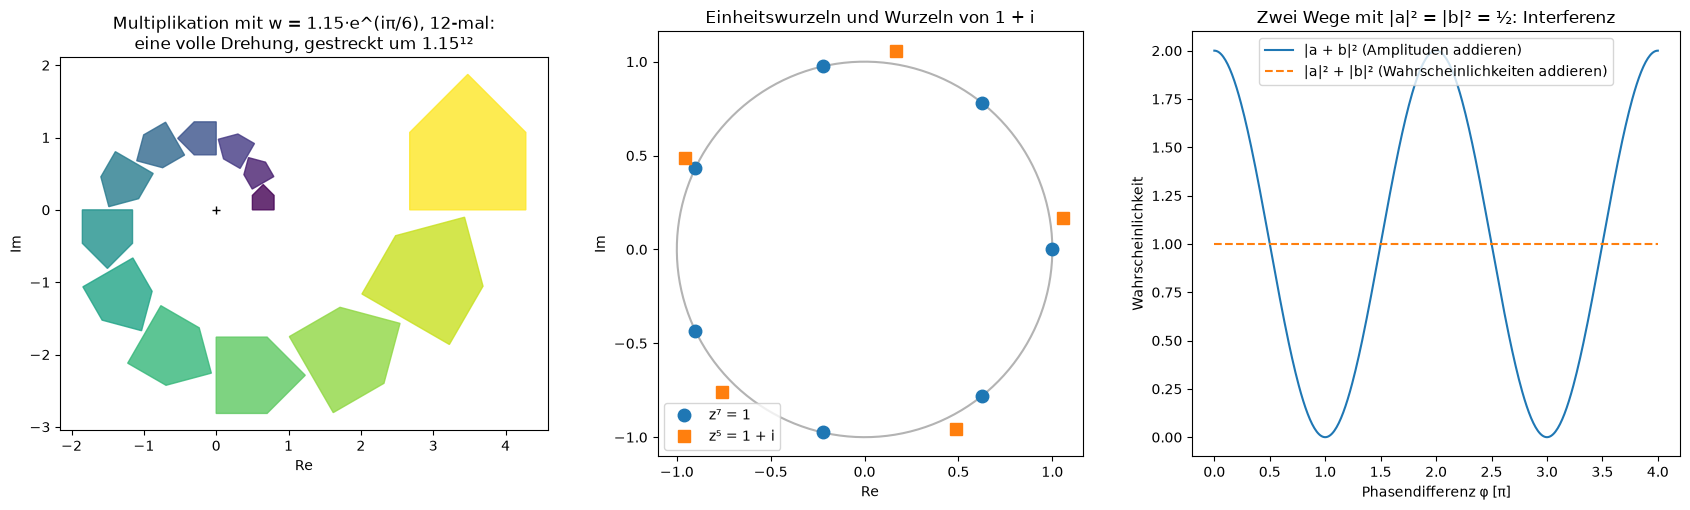

In [2]:
w = 1.15 * np.exp(1j * np.pi / 6)
haus = np.array([0, 0.3, 0.3 + 0.2j, 0.15 + 0.35j, 0.2j, 0]) + 0.5
M = np.array([[w.real, -w.imag], [w.imag, w.real]])               # dieselbe Zahl als reelle Matrix
z0 = 0.7 - 0.4j
print("Multiplikation als Matrix:", np.allclose(M @ [z0.real, z0.imag], [(w * z0).real, (w * z0).imag]),
      f"| e^(iπ) + 1 = {np.exp(1j * np.pi) + 1:.1e}")
wurzeln = np.exp(2j * np.pi * np.arange(7) / 7)
print("Summe der 7. Einheitswurzeln:", f"{abs(wurzeln.sum()):.1e}", "| Produkt:", np.round(np.prod(wurzeln), 12))

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
ax = axes[0]
for k in range(13):
    h = haus * w ** k
    ax.fill(h.real, h.imag, color=plt.get_cmap("viridis")(k / 12), alpha=0.8)
ax.plot(0, 0, "k+")
ax.set_aspect("equal"); ax.set_xlabel("Re"); ax.set_ylabel("Im")
ax.set_title("Multiplikation mit w = 1.15·e^(iπ/6), 12-mal:\neine volle Drehung, gestreckt um 1.15¹²")
ax = axes[1]
t = np.linspace(0, 2 * np.pi, 300)
ax.plot(np.cos(t), np.sin(t), color="0.7")
ax.plot(wurzeln.real, wurzeln.imag, "o", ms=9, label="z⁷ = 1")
loes = (1 + 1j) ** (1 / 5) * np.exp(2j * np.pi * np.arange(5) / 5)
ax.plot(loes.real, loes.imag, "s", ms=8, label="z⁵ = 1 + i")
ax.set_aspect("equal"); ax.legend(loc="lower left"); ax.set_xlabel("Re"); ax.set_ylabel("Im")
ax.set_title("Einheitswurzeln und Wurzeln von 1 + i")
ax = axes[2]
phi = np.linspace(0, 4 * np.pi, 400)
a, b_ = 1 / np.sqrt(2), np.exp(1j * phi) / np.sqrt(2)
ax.plot(phi / np.pi, np.abs(a + b_) ** 2, label="|a + b|² (Amplituden addieren)")
ax.plot(phi / np.pi, np.abs(a) ** 2 + np.abs(b_) ** 2, "--", label="|a|² + |b|² (Wahrscheinlichkeiten addieren)")
ax.set_xlabel("Phasendifferenz φ [π]"); ax.set_ylabel("Wahrscheinlichkeit")
ax.set_title("Zwei Wege mit |a|² = |b|² = ½: Interferenz"); ax.legend()
plt.tight_layout()
plt.show()

##### *2. Phasenbilder: Nullstellen und Pole sehen*

Wie erkennt man in einem Phasenbild Nullstellen, Pole und ihre Ordnung? Im Bild läuft die Farbe um eine Nullstelle der Ordnung $m$ $m$-mal gegen den Uhrzeigersinn durch rot–gelb–grün–blau, um einen Pol in umgekehrter Reihenfolge; die hellen Ringe sind Höhenlinien von $\vert f\vert$. Vorher vorhersagen: Was zeigt das Bild von $e^z$, das keine Nullstellen hat?

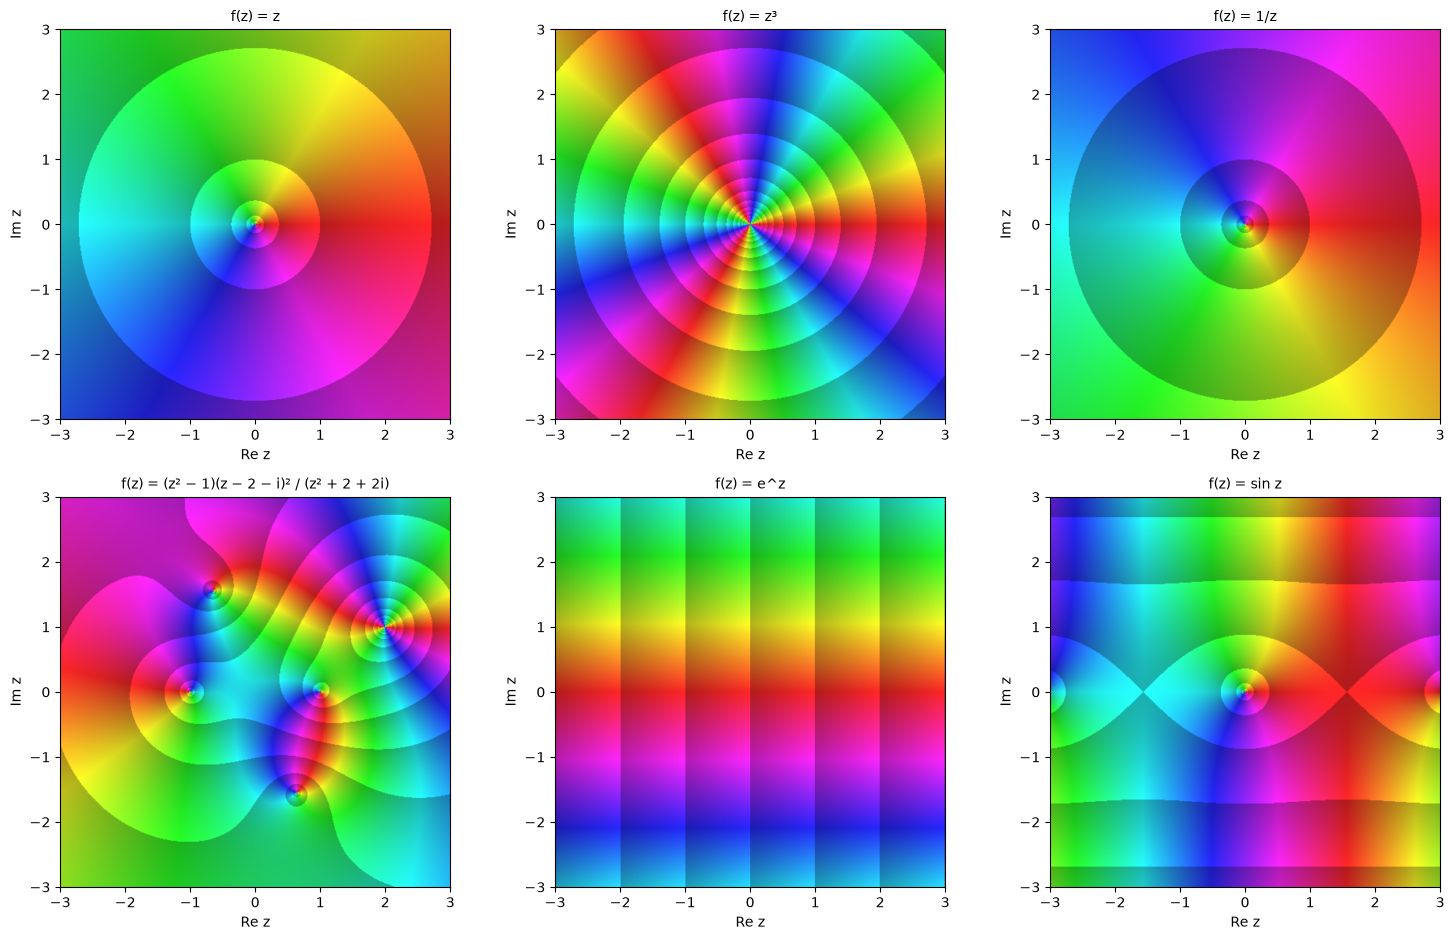

Nullstelle 1   bei 1.000+0.000j: Umlaufzahl des Bildes eines kleinen Kreises +1
Nullstelle −1  bei -1.000+0.000j: Umlaufzahl des Bildes eines kleinen Kreises +1
Nullstelle 2+i bei 2.000+1.000j: Umlaufzahl des Bildes eines kleinen Kreises +2
Pol            bei 0.644-1.554j: Umlaufzahl des Bildes eines kleinen Kreises -1
Pol            bei -0.644+1.554j: Umlaufzahl des Bildes eines kleinen Kreises -1


In [3]:
beispiele = {
    "f(z) = z": lambda z: z,
    "f(z) = z³": lambda z: z ** 3,
    "f(z) = 1/z": lambda z: 1 / z,
    "f(z) = (z² − 1)(z − 2 − i)² / (z² + 2 + 2i)": lambda z: (z ** 2 - 1) * (z - 2 - 1j) ** 2 / (z ** 2 + 2 + 2j),
    "f(z) = e^z": np.exp,
    "f(z) = sin z": np.sin,
}
fig, axes = plt.subplots(2, 3, figsize=(15, 9.5))
for ax, (name, f) in zip(axes.flat, beispiele.items()):
    phasenbild(ax, f, (-3, 3), (-3, 3))
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.show()

f = beispiele["f(z) = (z² − 1)(z − 2 − i)² / (z² + 2 + 2i)"]
pole = np.roots([1, 0, 2 + 2j])
for name, p in [("Nullstelle 1", 1), ("Nullstelle −1", -1), ("Nullstelle 2+i", 2 + 1j), ("Pol", pole[0]), ("Pol", pole[1])]:
    w_ = f(p + 0.05 * np.exp(2j * np.pi * np.arange(400) / 400))
    print(f"{name:14s} bei {complex(p):.3f}: Umlaufzahl des Bildes eines kleinen Kreises {umlaufzahl(w_):+.0f}")

##### *3. Holomorphie: Cauchy–Riemann, Winkeltreue und Strömungen*

Welche Funktionen erfüllen die Cauchy–Riemann-Gleichungen, bleiben rechte Winkel unter $z^2$ erhalten (und wo nicht), und wie sieht die Strömung um ein Tragflächenprofil aus, das die Joukowski-Abbildung $z = \zeta + 1/\zeta$ aus einem Kreis macht? Vorher überlegen: Wo ist $z^2$ nicht winkeltreu?

z²    : größter Cauchy-Riemann-Rest an 20 Zufallspunkten 5.6e-10
e^z   : größter Cauchy-Riemann-Rest an 20 Zufallspunkten 1.0e-09
sin z : größter Cauchy-Riemann-Rest an 20 Zufallspunkten 4.4e-10
1/z   : größter Cauchy-Riemann-Rest an 20 Zufallspunkten 6.7e-10
z̄    : größter Cauchy-Riemann-Rest an 20 Zufallspunkten 2.0e+00
|z|²  : größter Cauchy-Riemann-Rest an 20 Zufallspunkten 4.5e+00
Re z  : größter Cauchy-Riemann-Rest an 20 Zufallspunkten 1.0e+00
Winkel der Bildkurven unter z²: [90.     90.0001 90.     90.     90.    ] Grad; bei z = 0: 180 Grad (z² verdoppelt Winkel, f'(0) = 0)
Zirkulation nach der Kutta-Bedingung Γ = 2.8843, Auftrieb pro Länge ρUΓ = 2.8843·ρU² (Kutta–Joukowski)


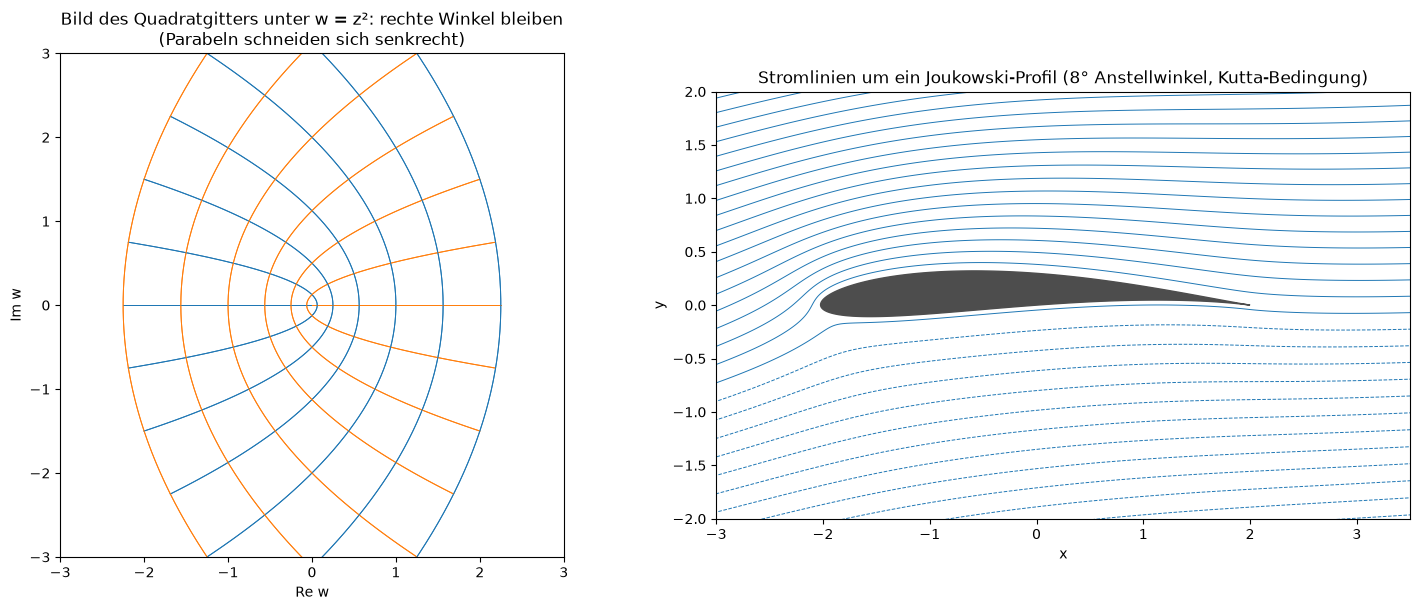

In [4]:
def cr_rest(f, z, h=1e-6):
    """|u_x − v_y| + |u_y + v_x| mit zentralen Differenzen."""
    fx = (f(z + h) - f(z - h)) / (2 * h)
    fy = (f(z + 1j * h) - f(z - 1j * h)) / (2 * h)
    return abs(fx.real - fy.imag) + abs(fy.real + fx.imag)


punkte = rng.normal(size=20) + 1j * rng.normal(size=20)
for name, f in [("z²", lambda z: z ** 2), ("e^z", np.exp), ("sin z", np.sin), ("1/z", lambda z: 1 / z),
                ("z̄", np.conj), ("|z|²", lambda z: abs(z) ** 2 + 0j), ("Re z", lambda z: z.real + 0j)]:
    print(f"{name:6s}: größter Cauchy-Riemann-Rest an 20 Zufallspunkten {max(cr_rest(f, z) for z in punkte):.1e}")

# Winkel zwischen den Bildern der Gitterlinien unter z ↦ z²
def bildwinkel(z, h=1e-6):
    d1 = (z + h) ** 2 - z ** 2
    d2 = (z + 1j * h) ** 2 - z ** 2
    return np.degrees(abs(np.angle(d2 / d1)))
print("Winkel der Bildkurven unter z²:", np.round([bildwinkel(z) for z in punkte[:5]], 4), "Grad;",
      f"bei z = 0: {np.degrees(abs(np.angle((1j * 1e-6) ** 2 / (1e-6) ** 2))):.0f} Grad (z² verdoppelt Winkel, f'(0) = 0)")

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
ax = axes[0]
s = np.linspace(-1.5, 1.5, 13)
t = np.linspace(-1.5, 1.5, 300)
for c in s:
    for linie, farbe in [(c + 1j * t, "tab:blue"), (t + 1j * c, "tab:orange")]:
        bild = linie ** 2
        ax.plot(bild.real, bild.imag, color=farbe, lw=0.7)
ax.set_aspect("equal"); ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)
ax.set_xlabel("Re w"); ax.set_ylabel("Im w")
ax.set_title("Bild des Quadratgitters unter w = z²: rechte Winkel bleiben\n(Parabeln schneiden sich senkrecht)")

# Strömung um ein Joukowski-Profil
mu = -0.08 + 0.08j                                              # Mittelpunkt des Kreises in der ζ-Ebene
R = abs(1 - mu)                                                 # Kreis durch ζ = 1, das Bild ist die Hinterkante
U, alpha = 1.0, np.radians(8)                                   # Anströmung und Anstellwinkel


def dPhi(zeta, Gamma):
    return U * (np.exp(-1j * alpha) - R ** 2 * np.exp(1j * alpha) / (zeta - mu) ** 2) + 1j * Gamma / (2 * np.pi * (zeta - mu))


A0 = dPhi(1.0, 0.0)
Gamma = (-A0 / (dPhi(1.0, 1.0) - A0)).real                     # Kutta-Bedingung: Staupunkt an der Hinterkante
print(f"Zirkulation nach der Kutta-Bedingung Γ = {Gamma:.4f}, Auftrieb pro Länge ρUΓ = {Gamma:.4f}·ρU² (Kutta–Joukowski)")
rr, tt = np.meshgrid(np.linspace(R, 6 * R, 300), np.linspace(0, 2 * np.pi, 400))
zeta = mu + rr * np.exp(1j * tt)
Phi = U * ((zeta - mu) * np.exp(-1j * alpha) + R ** 2 * np.exp(1j * alpha) / (zeta - mu)) + 1j * Gamma / (2 * np.pi) * np.log(zeta - mu)
zz = zeta + 1 / zeta                                            # Joukowski-Abbildung
ax = axes[1]
ax.contour(zz.real, zz.imag, Phi.imag, levels=np.linspace(-3, 3, 41), colors="tab:blue", linewidths=0.7)
profil = mu + R * np.exp(1j * np.linspace(0, 2 * np.pi, 400))
profil = profil + 1 / profil
ax.fill(profil.real, profil.imag, color="0.3")
ax.set_aspect("equal"); ax.set_xlim(-3, 3.5); ax.set_ylim(-2, 2)
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("Stromlinien um ein Joukowski-Profil (8° Anstellwinkel, Kutta-Bedingung)")
plt.tight_layout()
plt.show()

##### *4. Cauchy-Satz, Integralformel und die Trapezregel*

Stimmen die Kurvenintegrale mit Cauchy überein, liefert die Integralformel alle Ableitungen auf einmal, und wie schnell konvergiert die Trapezregel für einen analytischen gegenüber einem nur zweimal differenzierbaren periodischen Integranden? Vorher vorhersagen: Welchen Wert hat $\oint\bar z\,dz$ über einen Kreis vom Radius 0.5?

∮ e^z, Kreis um 0.3+0.2i   = 0.000000-0.000000j   (erwartet 0.000000)
∮ z², Kreis um 0.3+0.2i    = 0.000000-0.000000j   (erwartet 0.000000)
∮ 1/z, 0 innen             = 0.000000+6.283185j   (erwartet 0.000000+6.283185j)
∮ 1/z², 0 innen            = 0.000000+0.000000j   (erwartet 0.000000)
∮ z̄ (nicht holomorph)     = -0.000000+1.570796j   (erwartet 0.000000+1.570796j)
Taylor-Koeffizienten von e^z aus der Cauchy-Formel (FFT, 128 Punkte), n!·c_n für n = 0..7: [1. 1. 1. 1. 1. 1. 1. 1.]
größter relativer Fehler |n!·c_n − 1| für n ≤ 30: 4.4e-10


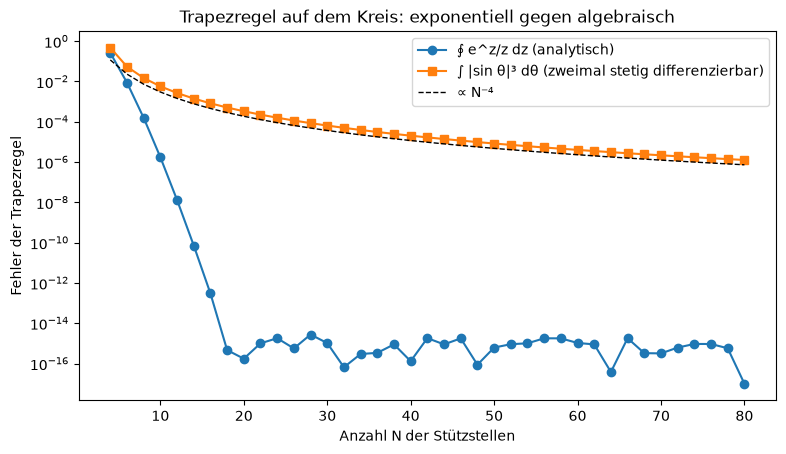

In [5]:
c, r = 0.3 + 0.2j, 0.5
for name, f, a, erwartet in [("e^z, Kreis um 0.3+0.2i", np.exp, c, 0), ("z², Kreis um 0.3+0.2i", lambda z: z ** 2, c, 0),
                              ("1/z, 0 innen", lambda z: 1 / z, c, 2j * np.pi), ("1/z², 0 innen", lambda z: z ** -2.0, c, 0),
                              ("z̄ (nicht holomorph)", np.conj, c, 2j * np.pi * r ** 2)]:
    print(f"∮ {name:24s} = {kreisintegral(f, a, r):.6f}   (erwartet {erwartet:.6f})")

kf = laurent(np.exp, 0, 10.0, 128)                              # Kreis vom Radius 10: alle c_n·rⁿ sind gut aufgelöst
print("Taylor-Koeffizienten von e^z aus der Cauchy-Formel (FFT, 128 Punkte), n!·c_n für n = 0..7:",
      np.round([math.factorial(n) * kf[n].real for n in range(8)], 12))
print(f"größter relativer Fehler |n!·c_n − 1| für n ≤ 30: {max(abs(math.factorial(n) * kf[n] - 1) for n in range(31)):.1e}")

N_werte = np.arange(4, 81, 2)
fehler_analytisch = [abs(kreisintegral(lambda z: np.exp(z) / z, 0, 1, N) - 2j * np.pi) for N in N_werte]
exakt_glatt = 8 / 3                                           # ∫ |sin θ|³ dθ über [0, 2π]
fehler_glatt = [abs(np.sum(np.abs(np.sin(2 * np.pi * np.arange(N) / N)) ** 3) * 2 * np.pi / N - exakt_glatt) for N in N_werte]

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.semilogy(N_werte, np.maximum(fehler_analytisch, 1e-17), "o-", label="∮ e^z/z dz (analytisch)")
ax.semilogy(N_werte, fehler_glatt, "s-", label="∫ |sin θ|³ dθ (zweimal stetig differenzierbar)")
ax.semilogy(N_werte, 30.0 * N_werte ** -4.0, "k--", lw=1, label="∝ N⁻⁴")
ax.set_xlabel("Anzahl N der Stützstellen"); ax.set_ylabel("Fehler der Trapezregel")
ax.set_title("Trapezregel auf dem Kreis: exponentiell gegen algebraisch"); ax.legend()
plt.show()

##### *5. Der Konvergenzradius: die Singularität, die man auf der reellen Achse nicht sieht*

$f(x) = 1/(1 + x^2)$ ist auf ganz $\mathbb R$ glatt und beschränkt. Warum divergiert ihre Taylor-Reihe um 0 trotzdem für $\vert x\vert>1$? Und stimmt der Konvergenzradius, geschätzt aus $\vert c_n\vert^{-1/n}$, für mehrere Funktionen mit dem Abstand zur nächsten Singularität überein? Vorher den Radius für $\tan z$ vorhersagen.

1/(1+z²)   : Schätzung bei n = 60: 1.000, Abstand zur nächsten Singularität 1.000
1/(4+z²)   : Schätzung bei n = 60: 2.000, Abstand zur nächsten Singularität 2.000
log(1+z)   : Schätzung bei n = 60: 1.070, Abstand zur nächsten Singularität 1.000
tan z      : Schätzung bei n = 60: 1.530, Abstand zur nächsten Singularität 1.571
1/(1−z+z²) : Schätzung bei n = 60: 1.000, Abstand zur nächsten Singularität 1.000


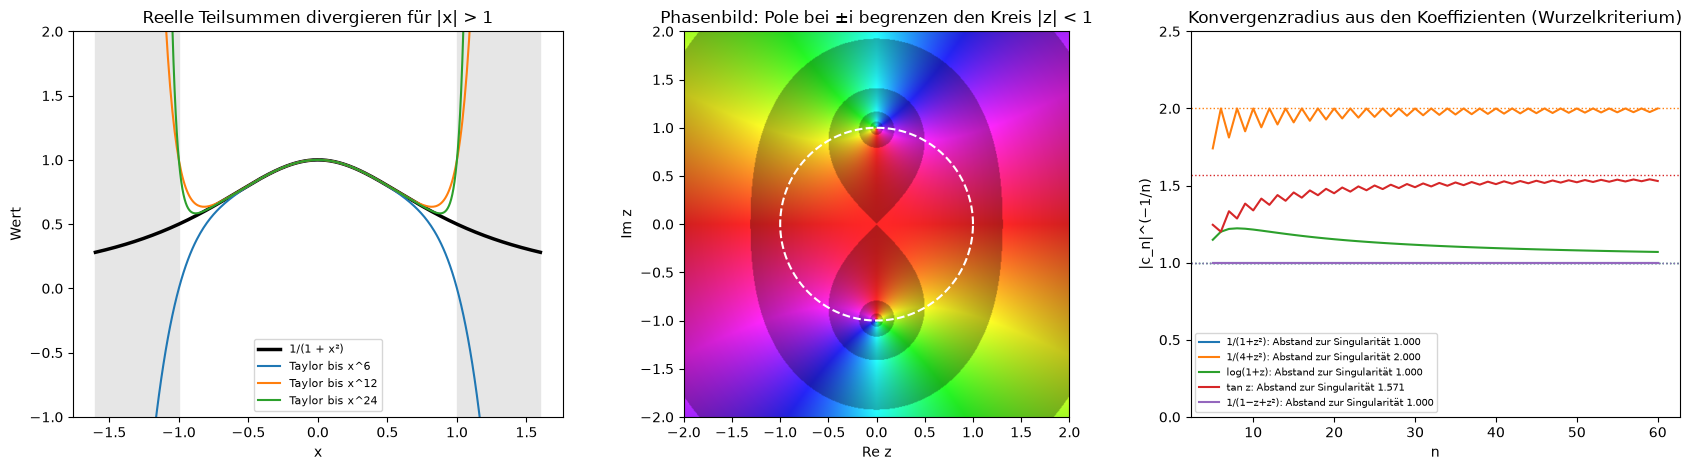

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
x = np.linspace(-1.6, 1.6, 400)
ax = axes[0]
ax.plot(x, 1 / (1 + x ** 2), "k", lw=2.5, label="1/(1 + x²)")
for N in [6, 12, 24]:
    teil = sum((-1) ** k * x ** (2 * k) for k in range(N // 2 + 1))
    ax.plot(x, teil, label=f"Taylor bis x^{N}")
ax.axvspan(-1.6, -1, color="0.9"); ax.axvspan(1, 1.6, color="0.9")
ax.set_ylim(-1, 2); ax.set_xlabel("x"); ax.set_ylabel("Wert")
ax.set_title("Reelle Teilsummen divergieren für |x| > 1"); ax.legend(fontsize=8)
phasenbild(axes[1], lambda z: 1 / (1 + z ** 2), (-2, 2), (-2, 2))
t = np.linspace(0, 2 * np.pi, 300)
axes[1].plot(np.cos(t), np.sin(t), "w--", lw=1.5)
axes[1].set_title("Phasenbild: Pole bei ±i begrenzen den Kreis |z| < 1")

funktionen = {"1/(1+z²)": (lambda z: 1 / (1 + z ** 2), 1.0), "1/(4+z²)": (lambda z: 1 / (4 + z ** 2), 2.0),
              "log(1+z)": (lambda z: np.log(1 + z), 1.0), "tan z": (np.tan, np.pi / 2),
              "1/(1−z+z²)": (lambda z: 1 / (1 - z + z ** 2), 1.0)}
ax = axes[2]
n = np.arange(5, 61)
for name, (f, R_wahr) in funktionen.items():
    k = laurent(f, 0, 0.9 * R_wahr, 256)                         # Koeffizienten aus einem Kreis innerhalb des Radius
    schaetz = []
    for m in n:
        fenster = [abs(k[j]) for j in range(m - 3, m + 1) if abs(k[j]) > 1e-300]   # 4 Koeffizienten: Lücken (z. B. tan) überbrücken
        schaetz.append(max(fenster) ** (-1 / m) if fenster else np.nan)
    linie, = ax.plot(n, schaetz, label=f"{name}: Abstand zur Singularität {R_wahr:.3f}")
    ax.axhline(R_wahr, color=linie.get_color(), ls=":", lw=1)
    print(f"{name:11s}: Schätzung bei n = 60: {schaetz[-1]:.3f}, Abstand zur nächsten Singularität {R_wahr:.3f}")
ax.set_xlabel("n"); ax.set_ylabel("|c_n|^(−1/n)"); ax.set_ylim(0, 2.5)
ax.set_title("Konvergenzradius aus den Koeffizienten (Wurzelkriterium)"); ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

##### *6. Isolierte Singularitäten: hebbar, Pol, wesentlich*

Wie unterscheiden sich $\sin z/z$, $1/z^3$ und $e^{1/z}$ bei 0 im Phasenbild, in den Laurent-Koeffizienten und im Wachstum von $\vert f\vert$ auf kleinen Kreisen? Und nimmt $e^{1/z}$ in jeder Umgebung von 0 wirklich jeden Wert außer 0 an? Vorher vorhersagen: Wie verhalten sich Maximum und Minimum von $\vert e^{1/z}\vert$ auf dem Kreis $\vert z\vert = r$?

hebbar: sin z / z        : |c_n| für n = −6..2: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.1667]
Pol der Ordnung 3: 1/z³  : |c_n| für n = −6..2: [0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
wesentlich: e^(1/z)      : |c_n| für n = −6..2: [0.0014, 0.0083, 0.0417, 0.1667, 0.5, 1.0, 1.0, 0.0, 0.0]
zum Vergleich 1/n! für n = 6..0: [0.0014, 0.0083, 0.0417, 0.1667, 0.5, 1.0, 1.0]


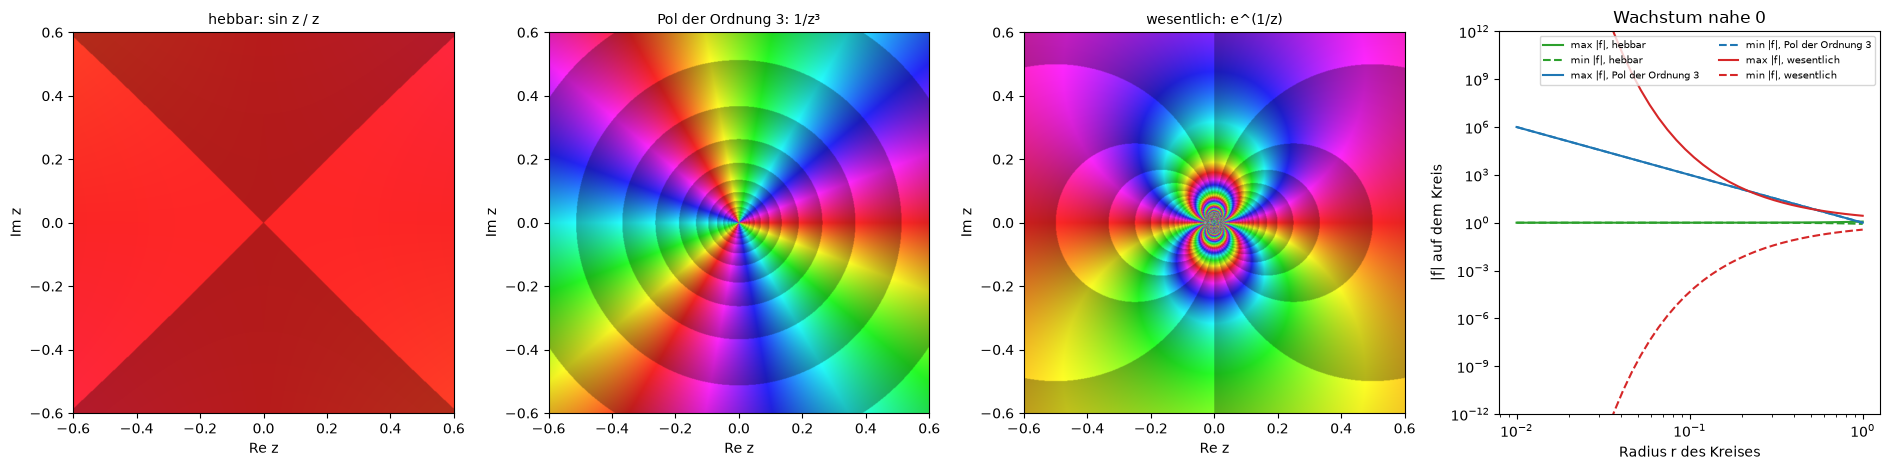

Lösungen von e^(1/z) = (2-3j): |z_k| = [0.1834 0.0858 0.0558 0.0413 0.0328], Probe |e^(1/z_k) − w| = 1.8e-14


In [7]:
singulaer = {"hebbar: sin z / z": lambda z: np.sin(z) / z, "Pol der Ordnung 3: 1/z³": lambda z: z ** -3.0,
             "wesentlich: e^(1/z)": lambda z: np.exp(1 / z)}
fig, axes = plt.subplots(1, 4, figsize=(19, 4.8))
for ax, (name, f) in zip(axes[:3], singulaer.items()):
    phasenbild(ax, f, (-0.6, 0.6), (-0.6, 0.6), n=700)
    ax.set_title(name, fontsize=10)
    k = laurent(f, 0, 0.3, 128)
    print(f"{name:25s}: |c_n| für n = −6..2: {[round(float(abs(k[j])), 4) for j in range(-6, 3)]}")
print("zum Vergleich 1/n! für n = 6..0:", [round(1 / math.factorial(j), 4) for j in range(6, -1, -1)])

ax = axes[3]
radien = np.logspace(-2, 0, 40)
th = np.linspace(0, 2 * np.pi, 2000, endpoint=False)
for (name, f), farbe in zip(singulaer.items(), ["tab:green", "tab:blue", "tab:red"]):
    betrag = np.array([np.abs(f(r_ * np.exp(1j * th))) for r_ in radien])
    art = name.split(":")[0]
    ax.loglog(radien, betrag.max(axis=1), color=farbe, label=f"max |f|, {art}")
    ax.loglog(radien, np.maximum(betrag.min(axis=1), 1e-300), color=farbe, ls="--", label=f"min |f|, {art}")
ax.set_ylim(1e-12, 1e12); ax.set_xlabel("Radius r des Kreises"); ax.set_ylabel("|f| auf dem Kreis")
ax.set_title("Wachstum nahe 0"); ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

ziel = 2 - 3j
loes = 1 / (np.log(ziel) + 2j * np.pi * np.arange(1, 6))
print(f"Lösungen von e^(1/z) = {ziel}: |z_k| = {np.round(np.abs(loes), 4)}, Probe |e^(1/z_k) − w| = "
      f"{np.max(np.abs(np.exp(1 / loes) - ziel)):.1e}")

##### *7. Verzweigungspunkte und Riemann-Flächen*

Was passiert mit $\sqrt z$ und $\log z$, wenn man sie stetig entlang eines Kreises um 0 fortsetzt, und wie sehen die Riemann-Flächen aus, auf denen sie eindeutige Funktionen werden? Vorher vorhersagen: Nach wie vielen Umläufen ist $\sqrt z$ wieder beim Startwert, nach wie vielen $\log z$?

nach 1 Umlauf/Umläufen: √z = -1.4142+0.0000j (Start 1.4142+0.0000j), log z = 0.6931+6.2832j (Start 0.6931+0.0000j)
nach 2 Umlauf/Umläufen: √z = 1.4142-0.0000j (Start 1.4142+0.0000j), log z = 0.6931+12.5664j (Start 0.6931+0.0000j)


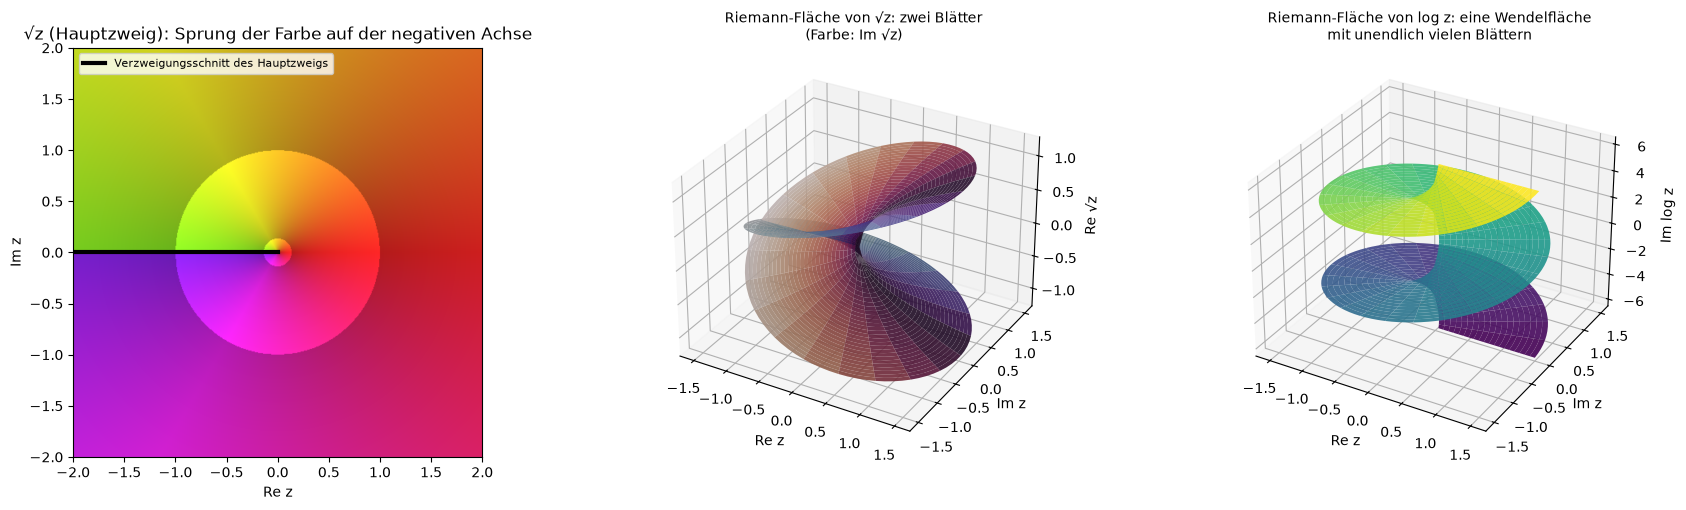

In [8]:
def fortsetzen(wurzel_von, z_weg, start):
    """Stetige Fortsetzung: in jedem Schritt den Zweig wählen, der dem vorigen Wert am nächsten liegt."""
    werte = [start]
    for z in z_weg[1:]:
        kandidaten = wurzel_von(z)
        werte.append(kandidaten[np.argmin(np.abs(kandidaten - werte[-1]))])
    return np.array(werte)


umlauf = 2 * np.exp(1j * np.linspace(0, 4 * np.pi, 2001))      # zwei Umläufe um 0
w_sqrt = fortsetzen(lambda z: np.array([np.sqrt(z), -np.sqrt(z)]), umlauf, np.sqrt(2 + 0j))
w_log = fortsetzen(lambda z: np.log(z) + 2j * np.pi * np.arange(-3, 4), umlauf, np.log(2 + 0j))
for k, idx in [(1, 1000), (2, 2000)]:
    print(f"nach {k} Umlauf/Umläufen: √z = {w_sqrt[idx]:.4f} (Start {w_sqrt[0]:.4f}), log z = {w_log[idx]:.4f} (Start {w_log[0]:.4f})")

fig = plt.figure(figsize=(18, 5.2))
ax = fig.add_subplot(1, 3, 1)
phasenbild(ax, np.sqrt, (-2, 2), (-2, 2))
ax.plot([-2, 0], [0, 0], "k", lw=3, label="Verzweigungsschnitt des Hauptzweigs")
ax.legend(loc="upper left", fontsize=8); ax.set_title("√z (Hauptzweig): Sprung der Farbe auf der negativen Achse")
ax = fig.add_subplot(1, 3, 2, projection="3d")
r_, t_ = np.meshgrid(np.linspace(0, 1.5, 30), np.linspace(0, 4 * np.pi, 160))
Z = r_ * np.exp(1j * t_)
W = np.sqrt(r_) * np.exp(1j * t_ / 2)                           # stetig über zwei Umläufe: beide Blätter
ax.plot_surface(Z.real, Z.imag, W.real, facecolors=plt.get_cmap("twilight")((W.imag / 1.3 + 1) / 2), lw=0, alpha=0.9)
ax.set_xlabel("Re z"); ax.set_ylabel("Im z"); ax.set_zlabel("Re √z")
ax.set_title("Riemann-Fläche von √z: zwei Blätter\n(Farbe: Im √z)", fontsize=10)
ax = fig.add_subplot(1, 3, 3, projection="3d")
r_, t_ = np.meshgrid(np.linspace(0.05, 1.5, 20), np.linspace(-2 * np.pi, 2 * np.pi, 200))
ax.plot_surface(r_ * np.cos(t_), r_ * np.sin(t_), t_, cmap="viridis", lw=0, alpha=0.9)
ax.set_xlabel("Re z"); ax.set_ylabel("Im z"); ax.set_zlabel("Im log z")
ax.set_title("Riemann-Fläche von log z: eine Wendelfläche\nmit unendlich vielen Blättern", fontsize=10)
plt.tight_layout()
plt.show()

##### *8. Der Residuensatz für reelle Integrale*

Stimmen reelle Integrale, die man über Halbkreise, Einheitskreis und Schlüssellochkontur mit Residuen berechnet, mit der numerischen Integration überein? Und wie verschwindet der Beitrag des großen Halbkreises, wenn sein Radius wächst? Vorher den Wert von $\int\frac{\cos2x}{1+x^2}dx$ aus dem Residuum bei $i$ berechnen.

∫ dx/(1+x²) über ℝ                     numerisch 3.1415926536, Residuen 3.1415926536, Differenz 0.0e+00  (Halbkreis, Pol i: 2πi·1/(2i))
∫ dx/(1+x⁴) über ℝ                     numerisch 2.2214414691, Residuen 2.2214414691, Differenz 4.4e-16  (Halbkreis, Pole e^(iπ/4), e^(3iπ/4))
∫ cos(2x)/(1+x²) über ℝ                numerisch 0.4251683316, Residuen 0.4251683316, Differenz 1.7e-11  (Halbkreis mit e^(2iz), Jordan)
∫ sin x / x über [0, ∞)                numerisch 1.5707963268, Residuen 1.5707963268, Differenz 5.2e-11  (Halbkreis mit Einbuchtung um 0)
∫ x^(a−1)/(1+x) über [0, ∞), a = 0.3   numerisch 3.8832220775, Residuen 3.8832220775, Differenz 4.4e-14  (Schlüsselloch um den Schnitt)
∫ dθ/(2 + cos θ) über [0, 2π]          numerisch 3.6275987285, Residuen 3.6275987285, Differenz 4.4e-16  (Einheitskreis z = e^(iθ))
Residuum von e^(2iz)/(1+z²) bei i, numerisch über einen kleinen Kreis: -0.00000000-0.06766764j, Formel e^(−2)/(2i) = 0.00000000-0.06766764j


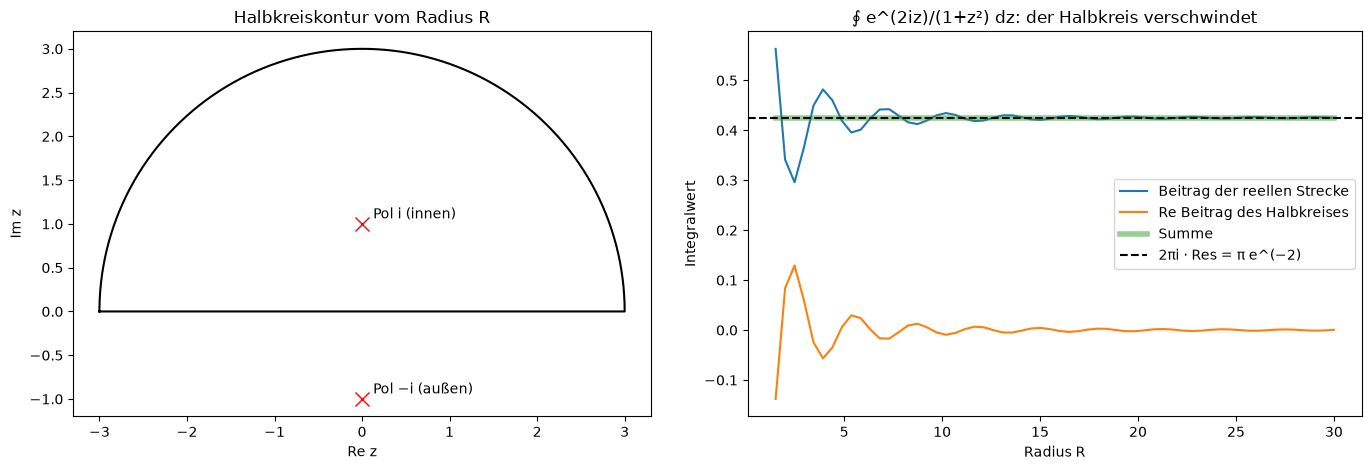

In [9]:
a_ = 0.3
integrale = [
    ("∫ dx/(1+x²) über ℝ", quad(lambda x: 1 / (1 + x ** 2), -np.inf, np.inf)[0], np.pi, "Halbkreis, Pol i: 2πi·1/(2i)"),
    ("∫ dx/(1+x⁴) über ℝ", quad(lambda x: 1 / (1 + x ** 4), -np.inf, np.inf)[0], np.pi / np.sqrt(2), "Halbkreis, Pole e^(iπ/4), e^(3iπ/4)"),
    ("∫ cos(2x)/(1+x²) über ℝ", 2 * quad(lambda x: 1 / (1 + x ** 2), 0, np.inf, weight="cos", wvar=2)[0], np.pi * np.exp(-2),
     "Halbkreis mit e^(2iz), Jordan"),
    ("∫ sin x / x über [0, ∞)", quad(lambda x: np.sinc(x / np.pi), 0, 1)[0] + quad(lambda x: 1 / x, 1, np.inf, weight="sin", wvar=1)[0],
     np.pi / 2, "Halbkreis mit Einbuchtung um 0"),
    ("∫ x^(a−1)/(1+x) über [0, ∞), a = 0.3", quad(lambda x: x ** (a_ - 1) / (1 + x), 0, 1)[0] + quad(lambda x: x ** (a_ - 1) / (1 + x), 1, np.inf)[0],
     np.pi / np.sin(np.pi * a_), "Schlüsselloch um den Schnitt"),
    ("∫ dθ/(2 + cos θ) über [0, 2π]", quad(lambda t: 1 / (2 + np.cos(t)), 0, 2 * np.pi)[0], 2 * np.pi / np.sqrt(3), "Einheitskreis z = e^(iθ)"),
]
for name, numerisch, formel, weg in integrale:
    print(f"{name:38s} numerisch {numerisch:.10f}, Residuen {formel:.10f}, Differenz {abs(numerisch - formel):.1e}  ({weg})")

print(f"Residuum von e^(2iz)/(1+z²) bei i, numerisch über einen kleinen Kreis: {kreisintegral(lambda z: np.exp(2j * z) / (1 + z ** 2), 1j, 0.3) / (2j * np.pi):.8f}, "
      f"Formel e^(−2)/(2i) = {np.exp(-2) / 2j:.8f}")

f = lambda z: np.exp(2j * z) / (1 + z ** 2)
radien = np.linspace(1.5, 30, 60)
gerade, bogen = [], []
for R_ in radien:
    gerade.append(quad(lambda x: f(x).real, -R_, R_, limit=200)[0])
    th = np.linspace(0, np.pi, 4001)
    z = R_ * np.exp(1j * th)
    bogen.append(trapezoid(f(z) * 1j * z, th))
gerade, bogen = np.array(gerade), np.array(bogen)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ax = axes[0]
th = np.linspace(0, np.pi, 200)
ax.plot(np.concatenate([[-3, 3], 3 * np.exp(1j * th).real]), np.concatenate([[0, 0], 3 * np.exp(1j * th).imag]), "k")
ax.plot([0, 0], [1, -1], "rx", ms=10); ax.annotate("Pol i (innen)", (0, 1), xytext=(8, 4), textcoords="offset points")
ax.annotate("Pol −i (außen)", (0, -1), xytext=(8, 4), textcoords="offset points")
ax.set_aspect("equal"); ax.set_xlabel("Re z"); ax.set_ylabel("Im z"); ax.set_title("Halbkreiskontur vom Radius R")
ax = axes[1]
ax.plot(radien, gerade, label="Beitrag der reellen Strecke")
ax.plot(radien, bogen.real, label="Re Beitrag des Halbkreises")
ax.plot(radien, gerade + bogen.real, lw=4, alpha=0.5, label="Summe")
ax.axhline(np.pi * np.exp(-2), color="k", ls="--", label="2πi · Res = π e^(−2)")
ax.set_xlabel("Radius R"); ax.set_ylabel("Integralwert")
ax.set_title("∮ e^(2iz)/(1+z²) dz: der Halbkreis verschwindet"); ax.legend()
plt.tight_layout()
plt.show()

##### *9. Argumentprinzip, Rouché und das Nyquist-Kriterium*

Wie viele Nullstellen von $p(z) = z^5 - 3z^3 + z - 0.5$ liegen in Kreisen verschiedener Radien, abgelesen allein an der Umlaufzahl des Bildes des Kreises? Und ab welcher Verstärkung $K$ wird der Regelkreis mit offenem Kreis $L(s) = K/(s+1)^3$ instabil? Vorher die kritische Verstärkung aus der Bedingung $L(i\omega) = -1$ ausrechnen.

|z| < 0.3: Umlaufzahl +0, Nullstellen laut np.roots: 0
|z| < 0.6: Umlaufzahl +2, Nullstellen laut np.roots: 2
|z| < 1.0: Umlaufzahl +3, Nullstellen laut np.roots: 3
|z| < 1.5: Umlaufzahl +3, Nullstellen laut np.roots: 3
|z| < 2.0: Umlaufzahl +5, Nullstellen laut np.roots: 5


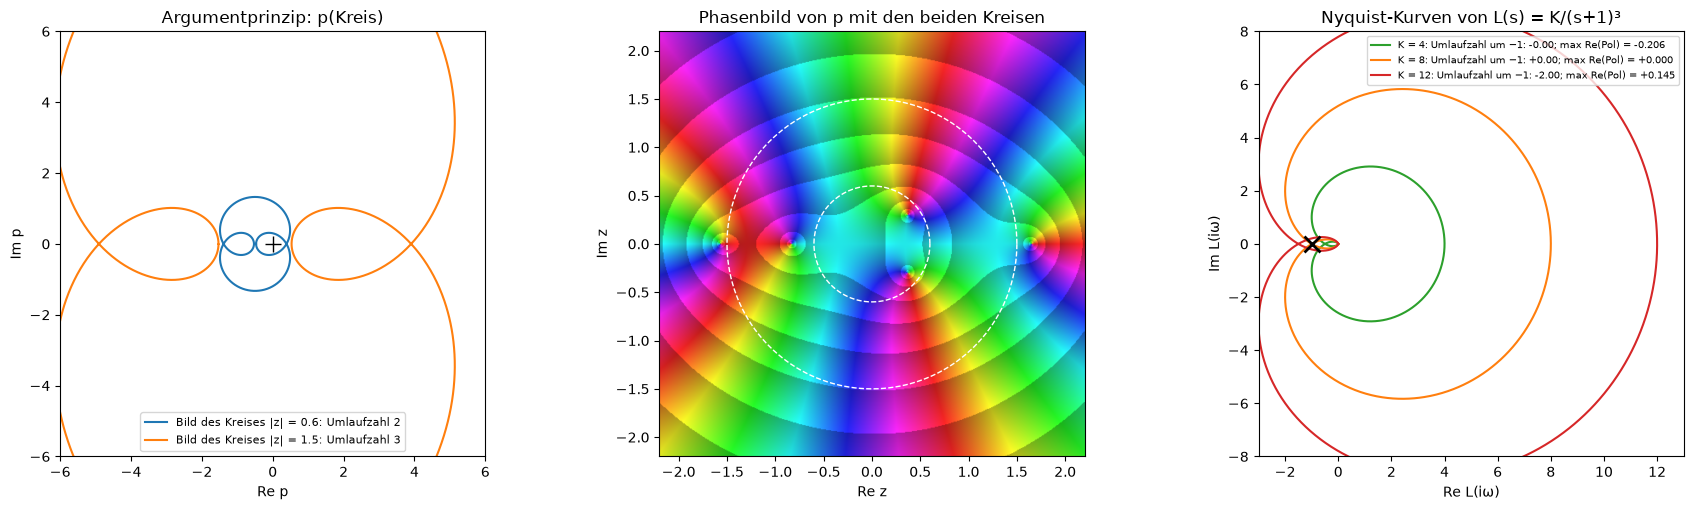

kritisch: L(iω) reell negativ bei 3·arctan ω = π, also ω = √3 und |L| = K/8: K_krit = 8


In [10]:
p = np.poly1d([1, 0, -3, 0, 1, -0.5])
wurzeln = p.roots
th = 2 * np.pi * np.arange(4000) / 4000
for R_ in [0.3, 0.6, 1.0, 1.5, 2.0]:
    print(f"|z| < {R_}: Umlaufzahl {umlaufzahl(p(R_ * np.exp(1j * th))):+.0f}, Nullstellen laut np.roots: {np.sum(np.abs(wurzeln) < R_)}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
ax = axes[0]
for R_, farbe in [(0.6, "tab:blue"), (1.5, "tab:orange")]:
    w_ = p(R_ * np.exp(1j * th))
    ax.plot(w_.real, w_.imag, color=farbe, label=f"Bild des Kreises |z| = {R_}: Umlaufzahl {umlaufzahl(w_):.0f}")
ax.plot(0, 0, "k+", ms=12)
ax.set_aspect("equal"); ax.set_xlim(-6, 6); ax.set_ylim(-6, 6)
ax.set_xlabel("Re p"); ax.set_ylabel("Im p"); ax.set_title("Argumentprinzip: p(Kreis)"); ax.legend(fontsize=8)
phasenbild(axes[1], p, (-2.2, 2.2), (-2.2, 2.2))
for R_ in [0.6, 1.5]:
    axes[1].plot(R_ * np.cos(th), R_ * np.sin(th), "w--", lw=1)
axes[1].set_title("Phasenbild von p mit den beiden Kreisen")

ax = axes[2]
omega = np.concatenate([-np.logspace(3, -3, 2000), np.logspace(-3, 3, 2000)])
for K, farbe in [(4, "tab:green"), (8, "tab:orange"), (12, "tab:red")]:
    L = K / (1j * omega + 1) ** 3
    pole_geschlossen = np.roots([1, 3, 3, 1 + K])
    ax.plot(L.real, L.imag, color=farbe,
            label=f"K = {K}: Umlaufzahl um −1: {umlaufzahl(L + 1):+.2f}; max Re(Pol) = {pole_geschlossen.real.max():+.3f}")
ax.plot(-1, 0, "kx", ms=12, mew=2)
ax.set_xlim(-3, 13); ax.set_ylim(-8, 8); ax.set_aspect("equal")
ax.set_xlabel("Re L(iω)"); ax.set_ylabel("Im L(iω)"); ax.set_title("Nyquist-Kurven von L(s) = K/(s+1)³"); ax.legend(fontsize=7)
plt.tight_layout()
plt.show()
print("kritisch: L(iω) reell negativ bei 3·arctan ω = π, also ω = √3 und |L| = K/8: K_krit = 8")

##### *10. Laplace-Transformation: Pole, Residuen und die Talbot-Kontur*

Stimmt die Sprungantwort eines gedämpften Oszillators, berechnet als Summe der Residuen von $X(s)e^{st}$, mit der numerischen Lösung der Differentialgleichung überein, für schwache, kritische und starke Dämpfung? Und wie invertiert man eine Transformierte mit Verzweigungsschnitt, $F(s) = e^{-a\sqrt s}/s$ (Wärmeleitung, Lösung $\mathrm{erfc}(a/2\sqrt t)$), für die es keine Residuensumme gibt? Vorher vorhersagen: Wo liegen die Pole bei kritischer Dämpfung?

schwach gedämpft, γ = 0.2 : Pole [-0.2-0.98j -0.2+0.98j  0. +0.j  ], größte Abweichung Residuen − ODE 5.0e-11
kritisch, γ = 1           : Pole [-1.  0.], größte Abweichung Residuen − ODE 1.0e-11
überdämpft, γ = 2         : Pole [-3.732 -0.268  0.   ], größte Abweichung Residuen − ODE 1.7e-11


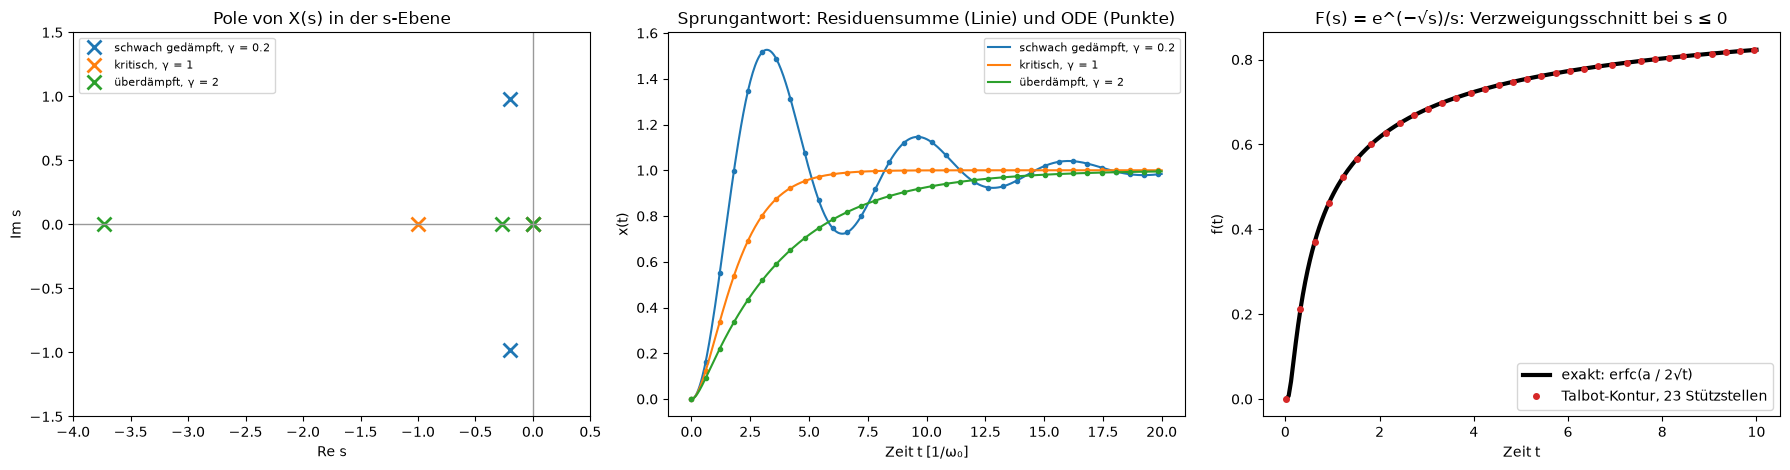

Talbot gegen erfc: größte Abweichung 4.3e-13


In [11]:
omega0 = 1.0
t = np.linspace(0, 20, 400)
faelle = {"schwach gedämpft, γ = 0.2": 0.2, "kritisch, γ = 1": 1.0, "überdämpft, γ = 2": 2.0}


def x_residuen(t, gam, r_kreis=0.05):
    """Summe der Residuen von X(s) e^(st), jedes numerisch als kleines Kreisintegral (funktioniert auch bei Doppelpolen)."""
    pole = np.unique(np.round(np.concatenate([[0.0], np.roots([1, 2 * gam, omega0 ** 2])]), 4))   # Doppelpol nur einmal
    X = lambda s: 1 / (s * (s ** 2 + 2 * gam * s + omega0 ** 2))
    return np.array([sum(kreisintegral(lambda s: X(s) * np.exp(s * tt), p_, r_kreis) / (2j * np.pi) for p_ in pole).real for tt in t]), pole


fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for (name, gam), farbe in zip(faelle.items(), ["tab:blue", "tab:orange", "tab:green"]):
    x_res, pole = x_residuen(t, gam)
    ode = solve_ivp(lambda tt, y: [y[1], 1 - 2 * gam * y[1] - omega0 ** 2 * y[0]], (0, 20), [0, 0], t_eval=t, rtol=1e-10, atol=1e-12)
    axes[1].plot(t, x_res, color=farbe, label=name)
    axes[1].plot(t[::12], ode.y[0][::12], "o", ms=3, color=farbe)
    axes[0].plot(pole.real, pole.imag, "x", ms=10, mew=2, color=farbe, label=name)
    print(f"{name:26s}: Pole {np.round(pole, 3)}, größte Abweichung Residuen − ODE {np.max(np.abs(x_res - ode.y[0])):.1e}")
axes[0].axvline(0, color="0.6", lw=1); axes[0].axhline(0, color="0.6", lw=1)
axes[0].set_xlabel("Re s"); axes[0].set_ylabel("Im s"); axes[0].set_title("Pole von X(s) in der s-Ebene")
axes[0].legend(fontsize=8); axes[0].set_xlim(-4, 0.5); axes[0].set_ylim(-1.5, 1.5)
axes[1].set_xlabel("Zeit t [1/ω₀]"); axes[1].set_ylabel("x(t)")
axes[1].set_title("Sprungantwort: Residuensumme (Linie) und ODE (Punkte)"); axes[1].legend(fontsize=8)

a_w = 1.0
F = lambda s: np.exp(-a_w * np.sqrt(s)) / s
tt = np.linspace(0.02, 10, 200)
f_talbot = np.array([talbot(F, x_) for x_ in tt])
axes[2].plot(tt, erfc(a_w / (2 * np.sqrt(tt))), "k", lw=3, label="exakt: erfc(a / 2√t)")
axes[2].plot(tt[::6], f_talbot[::6], "o", ms=4, color="tab:red", label="Talbot-Kontur, 23 Stützstellen")
axes[2].set_xlabel("Zeit t"); axes[2].set_ylabel("f(t)"); axes[2].set_title("F(s) = e^(−√s)/s: Verzweigungsschnitt bei s ≤ 0")
axes[2].legend()
plt.tight_layout()
plt.show()
print(f"Talbot gegen erfc: größte Abweichung {np.max(np.abs(f_talbot - erfc(a_w / (2 * np.sqrt(tt))))):.1e}")

##### *11. Kramers–Kronig: Kausalität bestimmt den Realteil aus dem Imaginärteil*

Ein gedämpfter Oszillator (Lorentz-Modell der Polarisierbarkeit) hat $\chi(\omega) = 1/(\omega_0^2 - \omega^2 - i\gamma\omega)$. Lässt sich der Realteil (Dispersion) allein aus dem Imaginärteil (Absorption) rekonstruieren, und ist die Antwort im Zeitbereich kausal? Vorher überlegen: In welcher Halbebene liegen die Pole?

Pole von χ: [ 0.9887-0.15j -0.9887-0.15j] (beide mit Im < 0)
größte Abweichung Re χ (Kramers–Kronig) − Re χ (exakt): 8.0e-09 (Rest vom endlichen Integrationsbereich)


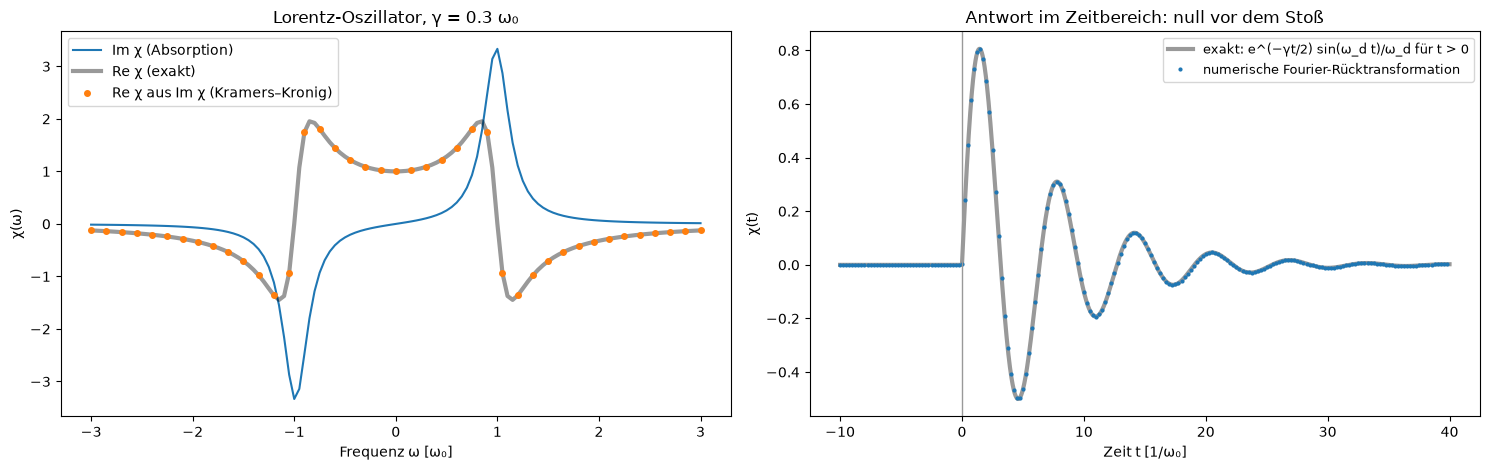

größter Betrag von χ(t) für t < 0 (numerisch): 1.5e-06


In [12]:
w0, gam = 1.0, 0.3
chi = lambda w: 1 / (w0 ** 2 - w ** 2 - 1j * gam * w)
print("Pole von χ:", np.round(np.roots([-1, -1j * gam, w0 ** 2]), 4), "(beide mit Im < 0)")

def kk_real(w):
    """Re χ(ω) = (1/π) P∫ Im χ(ω')/(ω' − ω) dω' (Hauptwert mit QUADPACK, Gewicht 'cauchy')."""
    L = 200.0
    return quad(lambda x: chi(x).imag, -L, L, weight="cauchy", wvar=w, limit=400)[0] / np.pi

omega = np.linspace(-3, 3, 121)
re_kk = np.array([kk_real(w) for w in omega])
print(f"größte Abweichung Re χ (Kramers–Kronig) − Re χ (exakt): {np.max(np.abs(re_kk - chi(omega).real)):.1e} "
      "(Rest vom endlichen Integrationsbereich)")

t = np.linspace(-10, 40, 2000)
wgit = np.linspace(-400, 400, 2 ** 18)
dw = wgit[1] - wgit[0]
chi_t = np.array([np.sum(chi(wgit) * np.exp(-1j * wgit * tt)).real * dw / (2 * np.pi) for tt in t[::10]])
wd = np.sqrt(w0 ** 2 - gam ** 2 / 4)
chi_t_exakt = np.where(t > 0, np.exp(-gam * t / 2) * np.sin(wd * t) / wd, 0.0)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].plot(omega, chi(omega).imag, label="Im χ (Absorption)")
axes[0].plot(omega, chi(omega).real, "k", lw=3, alpha=0.4, label="Re χ (exakt)")
axes[0].plot(omega[::3], re_kk[::3], "o", ms=4, label="Re χ aus Im χ (Kramers–Kronig)")
axes[0].set_xlabel("Frequenz ω [ω₀]"); axes[0].set_ylabel("χ(ω)"); axes[0].set_title("Lorentz-Oszillator, γ = 0.3 ω₀")
axes[0].legend()
axes[1].plot(t, chi_t_exakt, "k", lw=3, alpha=0.4, label="exakt: e^(−γt/2) sin(ω_d t)/ω_d für t > 0")
axes[1].plot(t[::10], chi_t, ".", ms=4, label="numerische Fourier-Rücktransformation")
axes[1].axvline(0, color="0.6", lw=1)
axes[1].set_xlabel("Zeit t [1/ω₀]"); axes[1].set_ylabel("χ(t)"); axes[1].set_title("Antwort im Zeitbereich: null vor dem Stoß")
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()
print(f"größter Betrag von χ(t) für t < 0 (numerisch): {np.max(np.abs(chi_t[t[::10] < -0.5])):.1e}")

##### *12. Die Resolvente: Projektoren, Zeitentwicklung und Zustandsdichte als Kurvenintegrale*

Für einen zufälligen hermiteschen $6\times6$-Hamilton-Operator: Gibt das Kurvenintegral der Resolvente um einen Eigenwert den Projektor auf seinen Eigenvektor, und um das ganze Spektrum mit $e^{-izt}$ den Zeitentwicklungsoperator? Wie sieht $-\frac1\pi\mathrm{Im}\,\mathrm{Tr}\,G(E + i\eta)$ für zwei Werte von $\eta$ aus? Vorher vorhersagen: Welche Fläche hat die Zustandsdichte?

Riesz-Projektor um E_2 = -1.005: Abweichung von |v><v| 4.5e-16, P² = P: True
e^(−iHt) für t = 1.7 als Kurvenintegral: Abweichung von expm 1.2e-13


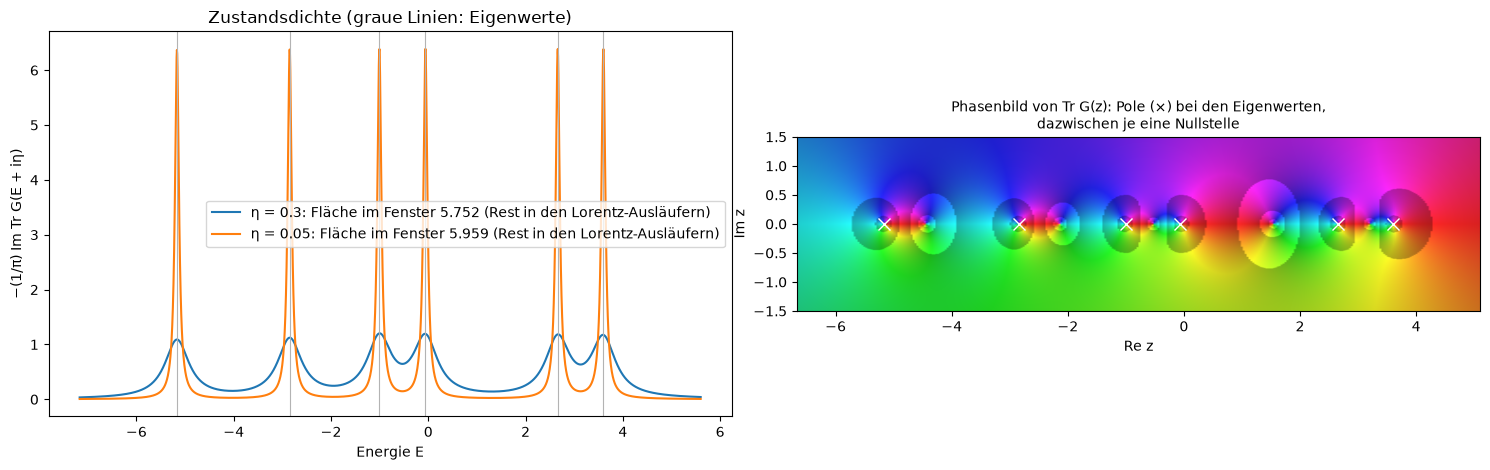

In [13]:
from scipy.linalg import expm
N = 6
A = rng.normal(size=(N, N)) + 1j * rng.normal(size=(N, N))
H = (A + A.conj().T) / 2
E, V = np.linalg.eigh(H)
G = lambda z: np.linalg.inv(z * np.eye(N) - H)


def matrix_kreisintegral(f, a, r, n=128):
    th = 2 * np.pi * np.arange(n) / n
    z = a + r * np.exp(1j * th)
    return sum(f(zz) * G(zz) * 1j * (zz - a) for zz in z) * 2 * np.pi / n / (2j * np.pi)


abstand = np.min(np.diff(E))
j = 2
P = matrix_kreisintegral(lambda z: 1.0, E[j], abstand / 2)
print(f"Riesz-Projektor um E_{j} = {E[j]:.3f}: Abweichung von |v><v| {np.max(np.abs(P - np.outer(V[:, j], V[:, j].conj()))):.1e}, "
      f"P² = P: {np.allclose(P @ P, P)}")
t0 = 1.7
mitte, radius = (E[0] + E[-1]) / 2, (E[-1] - E[0]) / 2 + 1.0
U = matrix_kreisintegral(lambda z: np.exp(-1j * z * t0), mitte, radius, n=256)
print(f"e^(−iHt) für t = {t0} als Kurvenintegral: Abweichung von expm {np.max(np.abs(U - expm(-1j * H * t0))):.1e}")

Eg = np.linspace(E[0] - 2, E[-1] + 2, 2000)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for eta in [0.3, 0.05]:
    rho = np.array([-np.trace(G(x + 1j * eta)).imag / np.pi for x in Eg])
    axes[0].plot(Eg, rho, label=f"η = {eta}: Fläche im Fenster {np.sum(rho) * (Eg[1] - Eg[0]):.3f} (Rest in den Lorentz-Ausläufern)")
for e in E:
    axes[0].axvline(e, color="0.7", lw=0.8)
axes[0].set_xlabel("Energie E"); axes[0].set_ylabel("−(1/π) Im Tr G(E + iη)")
axes[0].set_title("Zustandsdichte (graue Linien: Eigenwerte)"); axes[0].legend()
phasenbild(axes[1], np.vectorize(lambda z: np.trace(G(z))), (E[0] - 1.5, E[-1] + 1.5), (-1.5, 1.5), n=360)
axes[1].plot(E, 0 * E, "wx", ms=8)
axes[1].set_title("Phasenbild von Tr G(z): Pole (×) bei den Eigenwerten,\ndazwischen je eine Nullstelle", fontsize=10)
plt.tight_layout()
plt.show()

##### *13. Zerfall: ein Pol auf dem zweiten Blatt*

Ein Zustand $\vert0\rangle$ mit Energie 0 koppelt mit der Stärke $g = 0.05$ an 1600 gleichmäßig verteilte Niveaus auf $[-10, 10]$ (ein Modell für ein Atom, das in ein Kontinuum zerfällt). Fällt die Überlebenswahrscheinlichkeit exponentiell, und mit welcher Rate: der goldenen Regel $\Gamma = 2\pi g^2/\delta$, oder dem Imaginärteil des Pols der fortgesetzten Green-Funktion? Vorher vorhersagen: Wann kommt der Zustand zurück?

goldene Regel Γ = 1.2559; Pol auf dem zweiten Blatt z* = -0.00000-0.65403j, also Γ_Pol = 1.3081 (Näherung Γ/(1 − Γ/(πW)) = 1.3081)
Probe: auf dem ersten Blatt hat 1/(z − Σ(z)) in der unteren Halbebene dort keinen Pol: |z* − Σ_I(z*)| = 1.256
Fit der Überlebenswahrscheinlichkeit für 1 < t < 6: Γ = 1.3061; Rückkehrzeit 2π/δ = 502


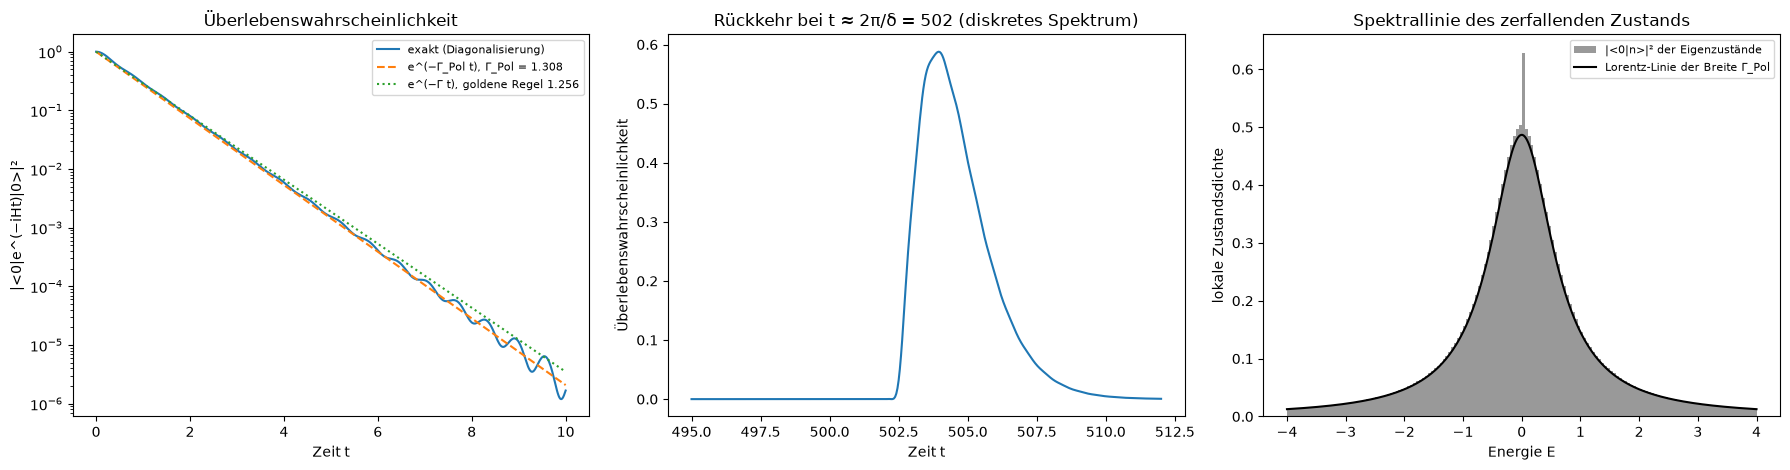

In [14]:
W, N_b, g = 10.0, 1600, 0.05
Eb = np.linspace(-W, W, N_b)
delta = Eb[1] - Eb[0]
H = np.zeros((N_b + 1, N_b + 1))
H[1:, 1:] = np.diag(Eb)
H[0, 1:] = H[1:, 0] = g
lam, V = np.linalg.eigh(H)
gewicht = np.abs(V[0]) ** 2                                       # |<0|n>|²: lokale Zustandsdichte

Gamma_gr = 2 * np.pi * g ** 2 / delta                            # Fermis goldene Regel
Sigma_II = lambda z: g ** 2 / delta * np.log((z + W) / (z - W)) - 2j * np.pi * g ** 2 / delta   # zweites Blatt (Im z < 0)
z = -0.5j * Gamma_gr
for _ in range(50):                                              # Newton für z − Σ_II(z) = 0
    F_ = z - Sigma_II(z)
    dF = 1 - g ** 2 / delta * (1 / (z + W) - 1 / (z - W))
    z = z - F_ / dF
Gamma_pol = -2 * z.imag
print(f"goldene Regel Γ = {Gamma_gr:.4f}; Pol auf dem zweiten Blatt z* = {z:.5f}, also Γ_Pol = {Gamma_pol:.4f} "
      f"(Näherung Γ/(1 − Γ/(πW)) = {Gamma_gr / (1 - Gamma_gr / (np.pi * W)):.4f})")
print(f"Probe: auf dem ersten Blatt hat 1/(z − Σ(z)) in der unteren Halbebene dort keinen Pol: "
      f"|z* − Σ_I(z*)| = {abs(z - (Sigma_II(z) + 2j * np.pi * g ** 2 / delta)):.3f}")

t = np.linspace(0, 10, 600)
amp = (gewicht[None, :] * np.exp(-1j * np.outer(t, lam))).sum(axis=1)
P_ueber = np.abs(amp) ** 2
m = (t > 1) & (t < 6)
Gamma_fit = -np.polyfit(t[m], np.log(P_ueber[m]), 1)[0]
print(f"Fit der Überlebenswahrscheinlichkeit für 1 < t < 6: Γ = {Gamma_fit:.4f}; Rückkehrzeit 2π/δ = {2 * np.pi / delta:.0f}")
t_lang = np.linspace(495, 512, 400)
P_lang = np.abs((gewicht[None, :] * np.exp(-1j * np.outer(t_lang, lam))).sum(axis=1)) ** 2

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].semilogy(t, P_ueber, label="exakt (Diagonalisierung)")
axes[0].semilogy(t, np.exp(-Gamma_pol * t), "--", label=f"e^(−Γ_Pol t), Γ_Pol = {Gamma_pol:.3f}")
axes[0].semilogy(t, np.exp(-Gamma_gr * t), ":", label=f"e^(−Γ t), goldene Regel {Gamma_gr:.3f}")
axes[0].set_xlabel("Zeit t"); axes[0].set_ylabel("|<0|e^(−iHt)|0>|²"); axes[0].set_title("Überlebenswahrscheinlichkeit")
axes[0].legend(fontsize=8)
axes[1].plot(t_lang, P_lang)
axes[1].set_xlabel("Zeit t"); axes[1].set_ylabel("Überlebenswahrscheinlichkeit")
axes[1].set_title(f"Rückkehr bei t ≈ 2π/δ = {2 * np.pi / delta:.0f} (diskretes Spektrum)")
bins = np.linspace(-4, 4, 161)
axes[2].hist(lam, bins=bins, weights=gewicht / (bins[1] - bins[0]), color="0.6", label="|<0|n>|² der Eigenzustände")
xx = np.linspace(-4, 4, 400)
axes[2].plot(xx, (Gamma_pol / (2 * np.pi)) / (xx ** 2 + Gamma_pol ** 2 / 4), "k", label="Lorentz-Linie der Breite Γ_Pol")
axes[2].set_xlabel("Energie E"); axes[2].set_ylabel("lokale Zustandsdichte"); axes[2].set_title("Spektrallinie des zerfallenden Zustands")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

##### *14. Analytische Fortsetzung: Gamma, Zeta und $-\tfrac1{12}$*

Wo hat die Gamma-Funktion Pole, und welche Residuen? Wie verläuft $\zeta$ auf der reellen Achse und auf der kritischen Geraden $\mathrm{Re}\,s = \tfrac12$? Und taucht $-\tfrac1{12}$ als endlicher Rest der geglätteten Summe $\sum ne^{-\varepsilon n}$ auf? Vorher vorhersagen: Welches Vorzeichen hat $\zeta(s)$ zwischen $-2$ und $0$?

Res Γ bei s = −0: +1.000000 (Formel (−1)^n/n! = +1.000000)
Res Γ bei s = −1: -1.000000 (Formel (−1)^n/n! = -1.000000)
Res Γ bei s = −2: +0.500000 (Formel (−1)^n/n! = +0.500000)
Res Γ bei s = −3: -0.166667 (Formel (−1)^n/n! = -0.166667)
Γ(1/2)² = 3.1415926536 = π; Spiegelung Γ(s)Γ(1−s) sin(πs)/π bei s = 0.3+0.4i: 1.0000000000-0.0000000000j
ζ(−1) aus der Funktionalgleichung: -0.0833333333; mpmath: -0.0833333333; ζ(0) = -0.5000
ε = 0.1: Σ n e^(−εn) − 1/ε² = -0.08329168  (−1/12 = -0.08333333)
ε = 0.01: Σ n e^(−εn) − 1/ε² = -0.08333292  (−1/12 = -0.08333333)
ε = 0.001: Σ n e^(−εn) − 1/ε² = -0.08333333  (−1/12 = -0.08333333)


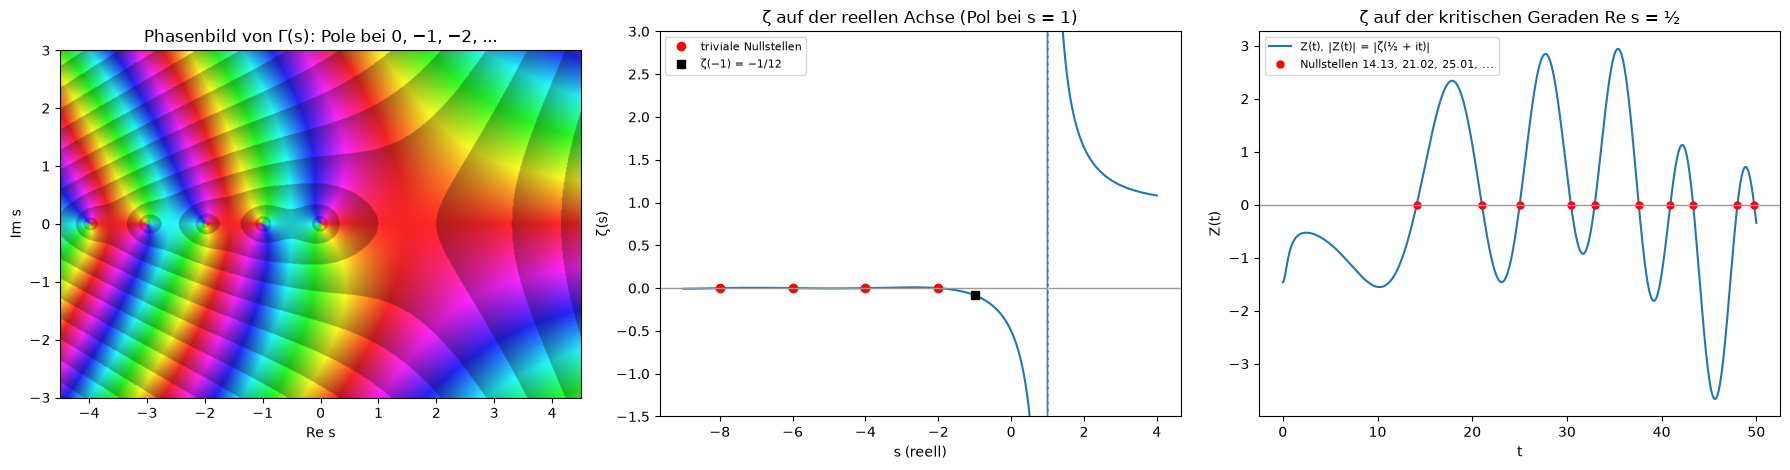

erste Nullstellen auf der kritischen Geraden: [14.1347 21.022  25.0109 30.4249 32.9351]


In [15]:
for n in range(4):
    res = kreisintegral(lambda s: gamma_fn(s), -n, 0.1) / (2j * np.pi)
    print(f"Res Γ bei s = −{n}: {res.real:+.6f} (Formel (−1)^n/n! = {(-1) ** n / math.factorial(n):+.6f})")
print(f"Γ(1/2)² = {gamma_fn(0.5) ** 2:.10f} = π; Spiegelung Γ(s)Γ(1−s) sin(πs)/π bei s = 0.3+0.4i: "
      f"{gamma_fn(0.3 + 0.4j) * gamma_fn(0.7 - 0.4j) * np.sin(np.pi * (0.3 + 0.4j)) / np.pi:.10f}")
z_m1 = 2 ** -1 * np.pi ** -2 * np.sin(-np.pi / 2) * gamma_fn(2) * (np.pi ** 2 / 6)
print(f"ζ(−1) aus der Funktionalgleichung: {z_m1:.10f}; mpmath: {float(mpmath.zeta(-1)):.10f}; ζ(0) = {float(mpmath.zeta(0)):.4f}")
for eps in [0.1, 0.01, 0.001]:
    n = np.arange(1, int(60 / eps))
    print(f"ε = {eps}: Σ n e^(−εn) − 1/ε² = {np.sum(n * np.exp(-eps * n)) - 1 / eps ** 2:+.8f}  (−1/12 = {-1 / 12:+.8f})")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
phasenbild(axes[0], gamma_fn, (-4.5, 4.5), (-3, 3), n=600)
axes[0].set_xlabel("Re s"); axes[0].set_ylabel("Im s")
axes[0].set_title("Phasenbild von Γ(s): Pole bei 0, −1, −2, ...")
sig = np.linspace(-9, 4, 1200)
zeta_reell = np.array([float(mpmath.zeta(s_)) if abs(s_ - 1) > 1e-3 else np.nan for s_ in sig])
axes[1].plot(sig, zeta_reell)
axes[1].plot([-2, -4, -6, -8], [0, 0, 0, 0], "ro", label="triviale Nullstellen")
axes[1].plot(-1, -1 / 12, "ks", label="ζ(−1) = −1/12")
axes[1].axhline(0, color="0.6", lw=1); axes[1].axvline(1, color="0.8", ls="--", lw=1)
axes[1].set_ylim(-1.5, 3); axes[1].set_xlabel("s (reell)"); axes[1].set_ylabel("ζ(s)")
axes[1].set_title("ζ auf der reellen Achse (Pol bei s = 1)"); axes[1].legend(fontsize=8)
tk = np.linspace(0, 50, 2000)
Zt = np.array([float(mpmath.siegelz(x_)) for x_ in tk])           # Hardy-Funktion: reell, |Z(t)| = |ζ(1/2 + it)|
nullst = [float(mpmath.zetazero(k).imag) for k in range(1, 11)]
axes[2].plot(tk, Zt, label="Z(t), |Z(t)| = |ζ(½ + it)|")
axes[2].plot(nullst, np.zeros(10), "ro", ms=5, label="Nullstellen 14.13, 21.02, 25.01, ...")
axes[2].axhline(0, color="0.6", lw=1)
axes[2].set_xlabel("t"); axes[2].set_ylabel("Z(t)"); axes[2].set_title("ζ auf der kritischen Geraden Re s = ½")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()
print("erste Nullstellen auf der kritischen Geraden:", np.round(nullst[:5], 4))

##### *15. Lee–Yang: Nullstellen der Zustandssumme*

Wo liegen die Nullstellen der Zustandssumme des Curie–Weiss-Modells in der komplexen Fugazitätsebene $z = e^{-2\beta h}$, für einen Ferromagneten unter und über der kritischen Kopplung $\beta J = 1$ und für einen Antiferromagneten? Wie nahe kommen sie dem Punkt $z = 1$ ($h = 0$), wenn $N$ wächst? Vorher vorhersagen: Was passiert mit dem Lee–Yang-Kreis bei $\beta J<0$?

Antiferromagnet: |z| reicht von 0.0155 bis 64.5


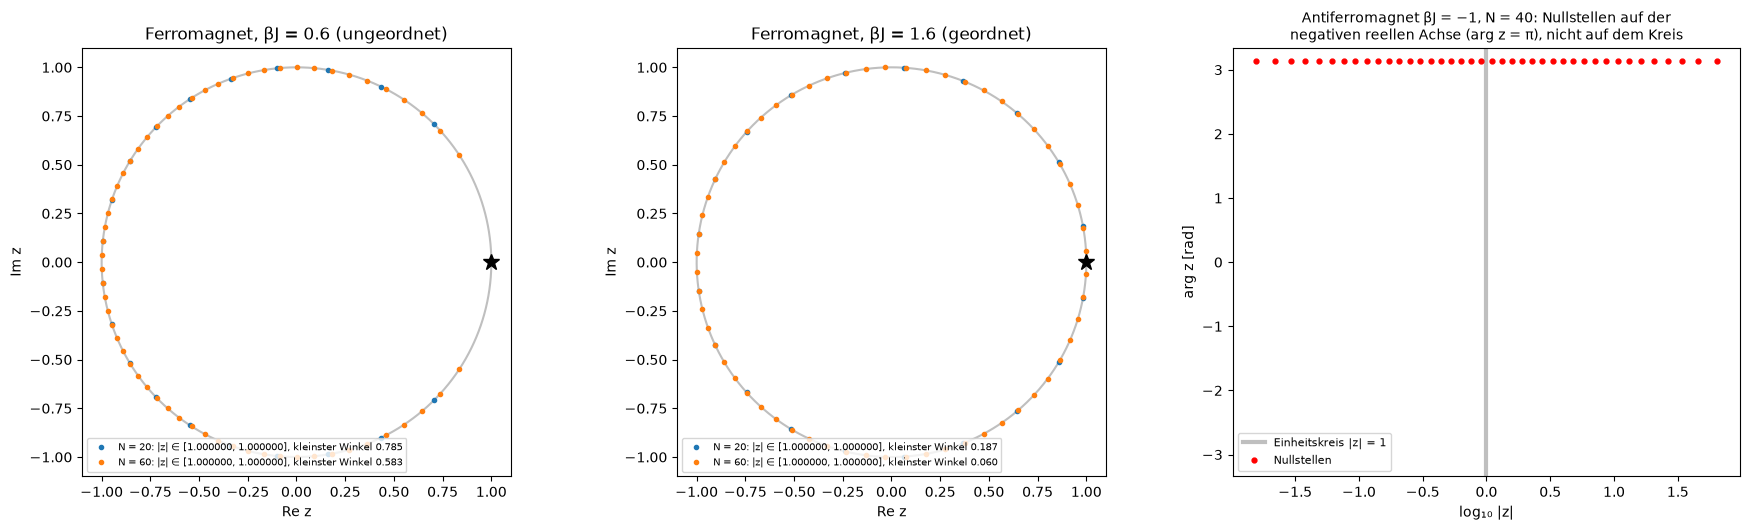

βJ = 0.6: kleinster Winkel der Nullstellen zur reellen Achse für N = 20, 40, 80: [0.7852 0.6414 0.5497]
βJ = 1.0: kleinster Winkel der Nullstellen zur reellen Achse für N = 20, 40, 80: [0.3755 0.2261 0.1356]
βJ = 1.6: kleinster Winkel der Nullstellen zur reellen Achse für N = 20, 40, 80: [0.1866 0.0903 0.0445]


In [16]:
mpmath.mp.dps = 80


def lee_yang(N, bJ):
    """Nullstellen von Z(z) = Σ_n C(N, n) exp(βJ/(2N)·((N−2n)² − N)) z^n (Herleitung 15), mit 80 Stellen gerechnet."""
    koef = [mpmath.binomial(N, n) * mpmath.exp(mpmath.mpf(bJ) / (2 * N) * ((N - 2 * n) ** 2 - N)) for n in range(N + 1)]
    return np.array([complex(r_) for r_ in mpmath.polyroots(koef[::-1], maxsteps=500, extraprec=400)])


fig, axes = plt.subplots(1, 3, figsize=(18, 5.4))
kreis = np.exp(1j * np.linspace(0, 2 * np.pi, 400))
for ax, (bJ, titel) in zip(axes[:2], [(0.6, "βJ = 0.6 (ungeordnet)"), (1.6, "βJ = 1.6 (geordnet)")]):
    ax.plot(kreis.real, kreis.imag, color="0.75")
    for N, farbe in [(20, "tab:blue"), (60, "tab:orange")]:
        nz = lee_yang(N, bJ)
        ax.plot(nz.real, nz.imag, ".", color=farbe, ms=6,
                label=f"N = {N}: |z| ∈ [{np.abs(nz).min():.6f}, {np.abs(nz).max():.6f}], kleinster Winkel {np.min(np.abs(np.angle(nz))):.3f}")
    ax.plot(1, 0, "k*", ms=12)
    ax.set_aspect("equal"); ax.set_xlabel("Re z"); ax.set_ylabel("Im z"); ax.set_title(f"Ferromagnet, {titel}")
    ax.legend(fontsize=7, loc="lower left")
nz = lee_yang(40, -1.0)
axes[2].axvline(0, color="0.75", lw=3, label="Einheitskreis |z| = 1")
axes[2].plot(np.log10(np.abs(nz)), np.angle(nz), "r.", ms=7, label="Nullstellen")
axes[2].set_ylim(-np.pi - 0.2, np.pi + 0.2)
axes[2].set_xlabel("log₁₀ |z|"); axes[2].set_ylabel("arg z [rad]")
axes[2].set_title("Antiferromagnet βJ = −1, N = 40: Nullstellen auf der\nnegativen reellen Achse (arg z = π), nicht auf dem Kreis", fontsize=10)
axes[2].legend(fontsize=8)
print(f"Antiferromagnet: |z| reicht von {np.abs(nz).min():.3g} bis {np.abs(nz).max():.3g}")
plt.tight_layout()
plt.show()

for bJ in [0.6, 1.0, 1.6]:
    winkel = [np.min(np.abs(np.angle(lee_yang(N, bJ)))) for N in [20, 40, 80]]
    print(f"βJ = {bJ}: kleinster Winkel der Nullstellen zur reellen Achse für N = 20, 40, 80: {np.round(winkel, 4)}")

#### **Ergebnis**

Beim Lauf vom 2026-10-13:

- **Komplexe Zahlen:** Die Multiplikation mit $w$ und die Drehstreckungsmatrix stimmen überein; zwölf Schritte mit $w = 1.15e^{i\pi/6}$ ergeben eine volle Drehung. Die siebten Einheitswurzeln summieren sich zu null. Zwei gleich starke Amplituden geben je nach Phase die Wahrscheinlichkeit 0 bis 2 statt konstant 1: Interferenz.
- **Phasenbilder:** Die Umlaufzahl des Bildes eines kleinen Kreises ist $+1$ an den einfachen Nullstellen $\pm1$, $+2$ an der doppelten Nullstelle $2 + i$ und $-1$ an den beiden Polen; genau das zeigen die Farbumläufe.
- **Holomorphie:** $z^2$, $e^z$, $\sin z$ und $1/z$ erfüllen Cauchy–Riemann bis auf den Fehler der Differenzen ($10^{-9}$), $\bar z$, $\vert z\vert^2$ und $\mathrm{Re}\,z$ verletzen sie deutlich. Unter $z^2$ schneiden sich die Bildkurven unter 90°, nur bei $z = 0$ ($f' = 0$) wird der Winkel verdoppelt. Für das Joukowski-Profil bei 8° gibt die Kutta-Bedingung die Zirkulation $\Gamma = 2.88$ und den Auftrieb $\rho U\Gamma$.
- **Cauchy:** Die Kreisintegrale geben genau 0 für holomorphe Integranden, $2\pi i$ für $1/z$ und $2i\cdot$Fläche $= 1.5708i$ für $\bar z$. Die FFT auf dem Kreis liefert die Taylor-Koeffizienten von $e^z$ bis $n = 30$ mit relativem Fehler $4\cdot10^{-10}$. Die Trapezregel konvergiert für den analytischen Integranden exponentiell (Maschinengenauigkeit ab etwa 20 Stützstellen), für $\vert\sin\theta\vert^3$ nur wie $N^{-4}$.
- **Konvergenzradius:** Die Taylor-Reihe von $1/(1+x^2)$ divergiert für $\vert x\vert>1$, weil die Pole $\pm i$ den Abstand 1 haben. $\vert c_n\vert^{-1/n}$ trifft bei $n = 60$ die Radien 1 und 2 exakt; bei $\log(1+z)$ (1.070) und $\tan z$ (1.530 statt $\pi/2$) nähert es sich langsam, wegen Faktoren wie $1/n$ in den Koeffizienten.
- **Singularitäten:** $\sin z/z$ hat keinen Hauptteil (hebbar, $\vert f\vert\approx1$), $1/z^3$ nur $c_{-3} = 1$ ($\vert f\vert\sim r^{-3}$), $e^{1/z}$ die Koeffizienten $1/n!$ für alle $n$. Für $e^{1/z}$ wachsen das Maximum auf kleinen Kreisen wie $e^{1/r}$ und das Minimum fällt wie $e^{-1/r}$; die Lösungen von $e^{1/z} = 2 - 3i$ häufen sich bei 0 ($\vert z_k\vert = 0.18, 0.086, 0.056, \dots$).
- **Verzweigung:** Nach einem Umlauf ist $\sqrt z$ beim negativen Startwert, nach zwei wieder am Start; $\log z$ gewinnt pro Umlauf $2\pi i$ und kehrt nie zurück.
- **Residuen:** Sechs reelle Integrale (Halbkreis, Jordan, Einbuchtung, Schlüsselloch, Einheitskreis) stimmen mit den Residuenformeln auf $10^{-11}$ oder besser überein. Für $e^{2iz}/(1+z^2)$ schwingt der Beitrag des Halbkreises mit wachsendem $R$ gegen 0; die Summe ist für jedes $R>1$ genau $\pi e^{-2}$.
- **Argumentprinzip:** Die Umlaufzahlen von $p(\text{Kreis})$ zählen die Nullstellen in Kreisen vom Radius 0.3 bis 2 richtig (0, 2, 3, 3, 5). Die Nyquist-Kurve geht für $K = 8$ genau durch $-1$; für $K = 12$ umläuft sie $-1$ zweimal, und der geschlossene Kreis hat zwei instabile Pole (Realteil $+0.145$).
- **Laplace:** Die Residuensumme stimmt für schwache, kritische (Doppelpol bei $-1$) und starke Dämpfung auf $5\cdot10^{-11}$ mit der Lösung der Differentialgleichung überein. Für $e^{-\sqrt s}/s$, das einen Verzweigungsschnitt hat, liefert die Talbot-Kontur mit 23 Stützstellen $\mathrm{erfc}(1/2\sqrt t)$ auf $4\cdot10^{-13}$.
- **Kramers–Kronig:** Beide Pole liegen in der unteren Halbebene; der aus dem Imaginärteil rekonstruierte Realteil stimmt auf $8\cdot10^{-9}$, und die Antwort im Zeitbereich verschwindet vor dem Stoß.
- **Resolvente:** Das Kurvenintegral um einen Eigenwert gibt den Projektor auf $5\cdot10^{-16}$ genau, das um das ganze Spektrum mit $e^{-izt}$ den Zeitentwicklungsoperator auf $10^{-13}$. Die Zustandsdichte hat Lorentz-Spitzen der Breite $\eta$ an den Eigenwerten.
- **Zerfall:** Die goldene Regel gibt $\Gamma = 1.256$, der Pol der auf das zweite Blatt fortgesetzten Green-Funktion liegt bei $-0.654i$, also $\Gamma_\text{Pol} = 1.308$, und der Fit an die exakte Überlebenswahrscheinlichkeit ergibt $1.306$. Die Abweichung von der goldenen Regel ist kein Rauschen, sondern die Krümmung des endlichen Bandes, und der Pol erfasst sie. Bei $t\approx502 = 2\pi/\delta$ kehrt der Zustand zurück, weil das Spektrum diskret ist.
- **Fortsetzung:** Die Residuen von $\Gamma$ bei $0, -1, -2, -3$ sind $1, -1, \tfrac12, -\tfrac16$. Die Funktionalgleichung gibt $\zeta(-1) = -\tfrac1{12}$ und die geglättete Summe $\sum ne^{-\varepsilon n} - 1/\varepsilon^2$ geht für $\varepsilon = 0.001$ auf acht Stellen gegen $-\tfrac1{12}$. Die ersten Nullstellen auf der kritischen Geraden liegen bei 14.13, 21.02, 25.01, 30.42, 32.94.
- **Lee–Yang:** Alle Nullstellen der ferromagnetischen Zustandssumme liegen auf dem Einheitskreis ($\vert z\vert = 1.000000$). Ihr Abstand zu $z = 1$ verhält sich je nach Phase verschieden: Bei $\beta J = 0.6$ fällt der kleinste Winkel nur langsam (0.79, 0.64, 0.55 für $N = 20, 40, 80$; eine Lücke bleibt), bei $\beta J = 1.6$ halbiert er sich mit jeder Verdopplung von $N$ (Nullstellen erreichen $z = 1$: Phasenübergang bei $h = 0$), beim kritischen $\beta J = 1$ fällt er um den Faktor 0.60 pro Verdopplung, also wie $N^{-3/4}$, dem Mean-Field-Exponenten. Beim Antiferromagneten liegen die Nullstellen dagegen auf der negativen reellen Achse, mit Beträgen von 0.016 bis 65.

#### **Variationen**

Jeweils zuerst die Vorhersage aufschreiben, dann den Code ändern.

1. **Wesentliche Singularität im Phasenbild** (Experiment 2): $\sin(1/z)$ auf $[-0.3, 0.3]^2$. Was sieht man nahe 0? *(Vorhersage: unendlich viele Nullstellen $1/(k\pi)$, die sich bei 0 häufen.)*
2. **Profil ohne Wölbung** (Experiment 3): Mittelpunkt $\mu = -0.08$ (reell). *(Vorhersage: symmetrisches Profil; bei 0° Anstellwinkel kein Auftrieb, $\Gamma = 0$.)*
3. **Polstelle nahe dem Kreis** (Experiment 4): $\oint\frac{dz}{z - 0.99}$ auf dem Einheitskreis mit wenigen Stützstellen. Warum braucht die Trapezregel jetzt viel mehr Punkte?
4. **Wurzelkriterium an $e^z$** (Experiment 5): Was liefert $\vert c_n\vert^{-1/n}$, und wie schnell wächst es?
5. **Kubikwurzel** (Experiment 7): $z^{1/3}$. *(Vorhersage: drei Umläufe bis zum Startwert.)*
6. **Totzeit im Regelkreis** (Experiment 9): $L(s) = Ke^{-s}/(s+1)$. Ab welchem $K$ umläuft die Nyquist-Kurve $-1$?
7. **Nicht kausales χ** (Experiment 11): Spiegle einen Pol in die obere Halbebene. Gilt Kramers–Kronig noch, und was passiert mit $\chi(t)$ für $t<0$?
8. **Rand des Bandes** (Experiment 13): Setze das Niveau auf $\varepsilon_0 = 9.5$, nahe der Bandkante. *(Vorhersage: deutliche Abweichungen von der exponentiellen Kurve, weil die Zustandsdichte dort nicht mehr konstant ist.)*
9. **Lee–Yang-Kante** (Experiment 15): Rechne für $\beta J = 0.6$ mit $N = 160$ und $320$. Geht der kleinste Winkel gegen einen festen Wert? *(Vorhersage: ja; in der ungeordneten Phase bleibt eine Lücke um $z = 1$, die Lee–Yang-Kante.)*

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Was sagen die Cauchy–Riemann-Gleichungen, und welche bekannten Funktionen erfüllen sie nicht?</summary>

$u_x = v_y$, $u_y = -v_x$, gleichwertig $\partial f/\partial\bar z = 0$. Nicht holomorph sind $\bar z$, $\vert z\vert^2$, $\mathrm{Re}\,z$: Sie hängen von $\bar z$ ab.
</details>

<details><summary>2. Warum ist eine holomorphe Funktion automatisch beliebig oft differenzierbar?</summary>

Die Cauchy-Integralformel schreibt $f$ als Integral über $f(z)/(z - a)$; nach $a$ darf man beliebig oft unter dem Integral ableiten.
</details>

<details><summary>3. Wovon hängt der Konvergenzradius einer Taylor-Reihe ab?</summary>

Vom Abstand zur nächsten Singularität in der komplexen Ebene, auch wenn sie nicht auf der reellen Achse liegt (bei $1/(1+x^2)$ die Pole $\pm i$).
</details>

<details><summary>4. Woran erkennt man hebbare Singularitäten, Pole und wesentliche Singularitäten?</summary>

An der Laurent-Reihe: kein, ein endlicher oder ein unendlicher Hauptteil. Hebbar heißt beschränkt nahe dem Punkt, Pol heißt $\vert f\vert\to\infty$, wesentlich heißt, $f$ kommt jedem Wert beliebig nahe (Casorati–Weierstraß) und nimmt fast jeden unendlich oft an (Picard).
</details>

<details><summary>5. Was ist ein Verzweigungspunkt, und was eine Riemann-Fläche?</summary>

Ein Punkt, nach dessen Umrundung man nicht zum Ausgangswert zurückkehrt ($\sqrt z\mapsto-\sqrt z$, $\log z\mapsto\log z + 2\pi i$). Auf der Riemann-Fläche, mehreren verklebten Blättern, wird die Funktion eindeutig.
</details>

<details><summary>6. Wie berechnet man ∫ dx/(1+x²) mit dem Residuensatz?</summary>

Mit einem Halbkreis oben schließen; der Pol $i$ hat das Residuum $1/(2i)$; das geschlossene Integral ist $2\pi i/(2i) = \pi$, der Bogen verschwindet wie $\pi R/(R^2 - 1)$.
</details>

<details><summary>7. Was misst das Argumentprinzip, und wie wird daraus das Nyquist-Kriterium?</summary>

$\frac1{2\pi i}\oint f'/f = N - P$, die Umlaufzahl von $f(\gamma)$ um 0. Für einen Regelkreis zählt die Umlaufzahl der Kurve $L(i\omega)$ um $-1$ die instabilen Pole des geschlossenen Kreises.
</details>

<details><summary>8. Wie hängen die Pole einer Laplace-Transformierten mit dem Zeitverlauf zusammen?</summary>

Jeder Pol $s_k$ gibt einen Term $e^{s_kt}$ (über sein Residuum); Polpaare $-\gamma\pm i\omega_d$ geben gedämpfte Schwingungen. Stabil heißt: alle Pole links der imaginären Achse.
</details>

<details><summary>9. Warum folgen die Kramers–Kronig-Relationen aus der Kausalität?</summary>

$\chi(t) = 0$ für $t<0$ macht $\chi(\omega)$ in der oberen Halbebene holomorph; die Cauchy-Formel mit einem Weg entlang der reellen Achse verknüpft dann Real- und Imaginärteil über Hauptwertintegrale.
</details>

<details><summary>10. Wie bekommt man Eigenprojektoren und e^(−iHt) aus der Resolvente?</summary>

$f(H) = \frac1{2\pi i}\oint f(z)(z - H)^{-1}dz$; um einen Eigenwert mit $f = 1$ gibt das den Projektor, um das ganze Spektrum mit $f = e^{-izt}$ die Zeitentwicklung.
</details>

<details><summary>11. Wo sitzt der Pol, der den exponentiellen Zerfall beschreibt?</summary>

Auf dem zweiten Blatt der Green-Funktion, bei $E_r - i\Gamma/2$, erreicht durch Fortsetzung über den Schnitt auf der reellen Achse. Die goldene Regel gibt $\Gamma = 2\pi g^2\rho$; das endliche Band verschiebt den Pol etwas.
</details>

<details><summary>12. In welchem Sinn ist 1 + 2 + 3 + … = −1/12?</summary>

Nur als Wert der analytisch fortgesetzten Zeta-Funktion bei $-1$. Die geglättete Summe $\sum ne^{-\varepsilon n} = 1/\varepsilon^2 - 1/12 + O(\varepsilon^2)$ hat $-\tfrac1{12}$ als glättungsunabhängigen endlichen Rest.
</details>

<details><summary>13. Was sagt der Satz von Lee und Yang?</summary>

Für Ising-Ferromagneten liegen alle Nullstellen der Zustandssumme in der Fugazität $z = e^{-2\beta h}$ auf dem Einheitskreis. Ein Phasenübergang braucht unendlich viele Spins und entsteht dort, wo die Nullstellen den Punkt $z = 1$ erreichen.
</details>

#### **Nächste Schritte**

- **Konforme Abbildungen weiter:** der Riemannsche Abbildungssatz, Schwarz–Christoffel-Abbildungen auf Polygone, Strömungen und Felder in Kanälen und um Kanten; Möbius-Abbildungen und die Riemann-Zahlenkugel im Notebook [Projektive Geometrie](https://github.com/deltorobarba/science/blob/main/maths/projectivegeometry.ipynb).
- **Sattelpunktmethode und Stationäre Phase:** asymptotische Auswertung von $\int e^{\lambda f(z)}dz$ (Stirling-Formel, Airy-Funktion, WKB, Pfadintegrale).
- **Elliptische Funktionen und Modulformen:** doppelt periodische Funktionen, der Zusammenhang mit elliptischen Kurven.
- **Riemann–Hilbert-Probleme und Wiener–Hopf:** Randwertprobleme in der komplexen Ebene; Zufallsmatrizen und integrable Systeme.
- **Mehrere komplexe Variablen und Quantenfeldtheorie:** Analytizität von Streuamplituden, Dispersionsrelationen, Wick-Rotation.
- **Primzahlsatz:** von den Nullstellen der Zeta-Funktion zur Verteilung der Primzahlen (explizite Formel von Riemann–von Mangoldt).

#### **Referenzen**

- T. Needham: *Visual Complex Analysis*, Oxford 1997 (Geometrie der komplexen Multiplikation, Differentiation als Drehstreckung, Cauchy-Satz, Strömungen).
- L. V. Ahlfors: *Complex Analysis*, 3. Aufl., McGraw-Hill 1979, Kapitel 2 (analytische Funktionen, Cauchy–Riemann), 4 (komplexe Integration; 4.5 Residuenkalkül), 5 (Reihen- und Produktentwicklungen).
- E. Wegert: *Visual Complex Functions: An Introduction with Phase Portraits*, Birkhäuser 2012.
- L. N. Trefethen, J. A. C. Weideman: *The exponentially convergent trapezoidal rule*, SIAM Review 56, 385 (2014).
- J. Abate, P. P. Valkó: *Multi-precision Laplace transform inversion*, Int. J. Numer. Meth. Eng. 60, 979 (2004).
- H. Nyquist: *Regeneration theory*, Bell Syst. Tech. J. 11, 126 (1932).
- J. S. Toll: *Causality and the dispersion relation: logical foundations*, Phys. Rev. 104, 1760 (1956).
- V. Weisskopf, E. Wigner: *Berechnung der natürlichen Linienbreite auf Grund der Diracschen Lichttheorie*, Z. Phys. 63, 54 (1930).
- E. N. Economou: *Green's Functions in Quantum Physics*, 3. Aufl., Springer 2006 (Resolvente, Selbstenergie, Zustandsdichte).
- D. J. Acheson: *Elementary Fluid Dynamics*, Oxford 1990 (klassische Profiltheorie, Joukowski-Abbildung, Kutta-Bedingung).
- B. Riemann: *Über die Anzahl der Primzahlen unter einer gegebenen Grösse*, Monatsberichte der Berliner Akademie (1859); H. M. Edwards: *Riemann's Zeta Function*, Academic Press 1974.
- T. Tao: *The Euler–Maclaurin formula, Bernoulli numbers, the zeta function, and real-variable analytic continuation*, Blogbeitrag (2010).
- T. D. Lee, C. N. Yang: *Statistical theory of equations of state and phase transitions. II. Lattice gas and Ising model*, Phys. Rev. 87, 410 (1952).